In [2]:
### Libaries
import sklearn
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.table as tb
from sklearn.datasets import fetch_california_housing, fetch_openml
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier, RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier, GradientBoostingRegressor, VotingClassifier, StackingClassifier
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import accuracy_score, root_mean_squared_error, mean_absolute_error, mean_squared_error, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.utils import resample
from scipy.stats import mode
from sklearn.inspection import permutation_importance

In [3]:
### Random Seed
RANDOM_SEEDS = [1,2,3,4,5]

In [4]:
### Data
fashionMNIST = fetch_openml('Fashion-MNIST')
californiaHousing = fetch_california_housing()

In [5]:
# split from last hw iris_utils
def stratified_split(X, y, test_fraction=0.3, seed=0):
    """Seeded, class-proportional train/test split."""
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for k in np.unique(y):
        idx_k = np.where(y == k)[0]
        rng.shuffle(idx_k)
        n_test_k = int(round(len(idx_k) * test_fraction))
        test_idx.extend(idx_k[:n_test_k])
        train_idx.extend(idx_k[n_test_k:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [7]:
# return the mean and standard deviation of a list of values
def mean_std(vals):
    n = len(vals)
    mu = sum(vals) / n

    s = 0
    for val in vals:
        s += (val-mu)**2
    std = (s / (n - 1))**0.5
    return (mu,std)

# given a list with [seeds][depth / other]
# return a list that has the (mean,std) tuples for the values
def calcStats(vals, sweep):
    stats = []
    # not a defined list, just get the length of the columns
    if sweep is None:
        sweep = range(len(vals[0]))
    # iterate by columns
    for i in range(len(sweep)):
        valuesAcrossDepth = []
        # iterate through seeds and calculate mean,std
        for l in range(len(RANDOM_SEEDS)):
            valuesAcrossDepth.append(vals[l][i])
        stats.append(mean_std(valuesAcrossDepth))
    return stats
# Just formatting the mean, std
def combine(stats):
    return ["{:.3f} ± {:.3f} ".format(mu, std) for mu, std in stats]

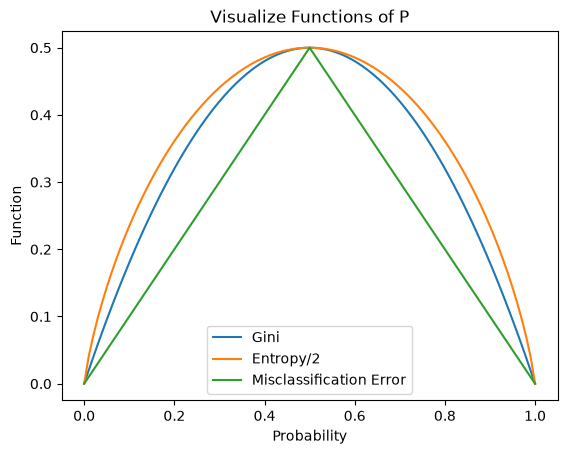

In [9]:
# part 1a - visualize the functions
# grab values 0 to 1 stepping 0.01
p = np.arange(0,1.01,0.01)
ginis = []
ents = []
misses = []
def gini(p):
    return 1 - p**2 - (1-p)**2
def ent(p):
    if p ==0 or p==1:
        return 0
    return -0.5*((p*np.log2(p)) + (1-p)*np.log2(1-p))
def mis(p):
    return 1 - max(p,1-p)

# calculate the functions
for val in p:
    ginis.append(gini(val))
    ents.append(ent(val))
    misses.append(mis(val))

# plot the results
plt.plot(p, ginis, label="Gini")
plt.plot(p, ents, label="Entropy/2")
plt.plot(p,misses, label="Misclassification Error")
plt.xlabel("Probability")
plt.ylabel("Function")
plt.title("Visualize Functions of P")
plt.legend(loc='lower center')

In [10]:
### part 1b - how often the two criteria choose the same feature at the root and at depth 1–2
def getFeaturesAtDepth1_2(model):
    tree = model.tree_
    features = {}

    # root
    if tree.feature[0] != -2:
        features[""] = tree.feature[0]

    # depth 1
    left = tree.children_left[0]
    right = tree.children_right[0]

    # make sure it exists
    if left != -1 and tree.feature[left] != -2:
        features["L"] = tree.feature[left]
    if right != -1 and tree.feature[right] != -2:
        features["R"] = tree.feature[right]

    # depth 2
    for node, path in [(left, "L"), (right, "R")]: # iterate to L, R, RR, RL, LL, LR
        if node == -1:
            continue

        left2 = tree.children_left[node]
        right2 = tree.children_right[node]

        # make sure exists
        if left2 != -1 and tree.feature[left2] != -2:
            features[path + "L"] = tree.feature[left2]
        if right2 != -1 and tree.feature[right2] != -2:
            features[path + "R"] = tree.feature[right2]

    return features

In [8]:
# classification - split data
xtrs = []
xvals = []
ytrs = []
yvals = []
xtes = []
ytes = []

for seed in RANDOM_SEEDS:
    # take 15k needed ~ 1/4 of dataset
    X = fashionMNIST.data[:15000].to_numpy()
    y = fashionMNIST.target[:15000].to_numpy()

    # split into 10,000 train, 5,000 val
    xtr, xval, ytr, yval = stratified_split(X, y, test_fraction=1/3, seed=seed)

    # take test
    xte = fashionMNIST.data[60000:].to_numpy()
    yte = fashionMNIST.target[60000:].to_numpy()

    xtrs.append(xtr)
    xvals.append(xval)
    ytrs.append(ytr)
    yvals.append(yval)
    xtes.append(xte)
    ytes.append(yte)

In [12]:
### Part 1b
entropyTrees = []
entropyTrainAccuracies = []
entropyValidationAccuracies = []
entropyTimes = []
entropyLeaves = []
entropyActualDepths = []
giniTrees = []
giniTrainAccuracies = []
giniValidationAccuracies = []
giniTimes = []
giniLeaves = []
giniActualDepths = []

for l in range(len(RANDOM_SEEDS)):
    print(seed)
    depths = [2,4,6,8,10,12,15,20,None]
    currEntropyTrees = []
    currEntropyTrainAccuracies = []
    currEntropyValidationAccuracies = []
    currEntropyTimes = []
    currEntropyLeaves = []
    currEntropyActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        entropyTree = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_SEEDS[l], max_depth=depth)
        entropyTree.fit(xtrs[l], ytrs[l])

        # training accuracy
        entropyTreePredictions = entropyTree.predict(xtrs[l])
        entropyTrainAccuracy = accuracy_score(ytrs[l], entropyTreePredictions)

        # validation accuracy
        entropyTreePredictions = entropyTree.predict(xvals[l])
        entropyValidationAccuracy = accuracy_score(yvals[l], entropyTreePredictions)

        # update lists
        end = time.time()
        currEntropyTimes.append(end-start)
        currEntropyTrainAccuracies.append(entropyTrainAccuracy)
        currEntropyValidationAccuracies.append(entropyValidationAccuracy)
        currEntropyLeaves.append(entropyTree.get_n_leaves())
        currEntropyTrees.append(entropyTree)
        currEntropyActualDepths.append(entropyTree.get_depth())

    print("Entropy Done")
    currGiniTrees = []
    currGiniTrainAccuracies = []
    currGiniValidationAccuracies = []
    currGiniTimes = []
    currGiniLeaves = []
    currGiniActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        giniTree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l], max_depth=depth)
        giniTree.fit(xtrs[l], ytrs[l])
        
        # training accuracy
        giniTreePredictions = giniTree.predict(xtrs[l])
        giniTrainError = accuracy_score(ytrs[l], giniTreePredictions)

        # validation accuracy
        giniTreePredictions = giniTree.predict(xvals[l])
        giniValidationError = accuracy_score(yvals[l], giniTreePredictions)

        # update lists
        end = time.time()
        currGiniTimes.append(end-start)
        currGiniTrainAccuracies.append(giniTrainError)
        currGiniValidationAccuracies.append(giniValidationError)
        currGiniLeaves.append(giniTree.get_n_leaves())
        currGiniActualDepths.append(giniTree.get_depth())
        currGiniTrees.append(giniTree)

    print("Gini Done")
    # append final values obtained
    entropyTrees.append(currEntropyTrees)
    entropyTrainAccuracies.append(currEntropyTrainAccuracies)
    entropyValidationAccuracies.append(currEntropyValidationAccuracies)
    entropyTimes.append(currEntropyTimes)
    entropyLeaves.append(currEntropyLeaves)
    entropyActualDepths.append(currEntropyActualDepths)
    giniTrees.append(currGiniTrees)
    giniTrainAccuracies.append(currGiniTrainAccuracies)
    giniValidationAccuracies.append(currGiniValidationAccuracies)
    giniTimes.append(currGiniTimes)
    giniLeaves.append(currGiniLeaves)
    giniActualDepths.append(currGiniActualDepths)


5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done


In [13]:
#just get the mean,std estimates
entropyTrainAccStats = calcStats(entropyTrainAccuracies, sweep=depths)
entropyValidationAccStats = calcStats(entropyValidationAccuracies, sweep=depths)
entropyTimeStats = calcStats(entropyTimes, sweep=depths)
entropyLeaveStats= calcStats(entropyLeaves, sweep=depths)
entropyAcDepthStats = calcStats(entropyActualDepths, sweep=depths)
giniTrainAccStats = calcStats(giniTrainAccuracies, sweep=depths)
giniValidationAccStats = calcStats(giniValidationAccuracies, sweep=depths)
giniTimeStats = calcStats(giniTimes, sweep=depths)
giniLeaveStats = calcStats(giniLeaves, sweep=depths)
giniAcDepthStats = calcStats(giniActualDepths, sweep=depths)

In [14]:
# Part 1c - matches at depth
# compare features located on both trees, at root, depth1, depth 2
rootList = []
depth1List = []
depth2list = []

for l in range(len(RANDOM_SEEDS)):
    matches = [0, 0, 0]
    totals = [0, 0, 0]

    for entropyTree, giniTree in zip(entropyTrees[l], giniTrees[l]):
        entropyFeatures = getFeaturesAtDepth1_2(entropyTree)
        giniFeatures = getFeaturesAtDepth1_2(giniTree)

        # total positions for both trees via union
        paths = entropyFeatures.keys() | giniFeatures.keys()

        for path in paths:
            depth = len(path)
            totals[depth] += 1

            # make sure path exists for both
            if path in entropyFeatures and path in giniFeatures:
                # if match increment matches at depth counter
                if entropyFeatures[path] == giniFeatures[path]:
                    matches[depth] += 1
                    
    # division by zero check
    if totals[0] > 0:
        rootList.append(matches[0] / totals[0])
    if totals[1] > 0:
        depth1List.append(matches[1] / totals[1])
    if totals[2] > 0:
        depth2list.append(matches[2] / totals[2])

#calculate estimates
rootMean, rootStd = mean_std(rootList)
depth1Mean, depth1Std = mean_std(depth1List)
depth2Mean, depth2Std = mean_std(depth2list)
totalmean, totalstd = mean_std(rootList + depth1List + depth2list)

print("Root agreement: {:.3f} ± {:.3f}".format(rootMean, rootStd))
print("Depth 1 agreement: {:.3f} ± {:.3f}".format(depth1Mean, depth1Std))
print("Depth 2 agreement: {:.3f} ± {:.3f}".format(depth2Mean, depth2Std))
print("Total agreement: {:.3f} ± {:.3f}".format(totalmean, totalstd))

Root agreement: 0.000 ± 0.000
Depth 1 agreement: 0.000 ± 0.000
Depth 2 agreement: 0.050 ± 0.112
Total agreement: 0.017 ± 0.065


Text(0.5, 1.0, 'Train Accuracy vs Depth')

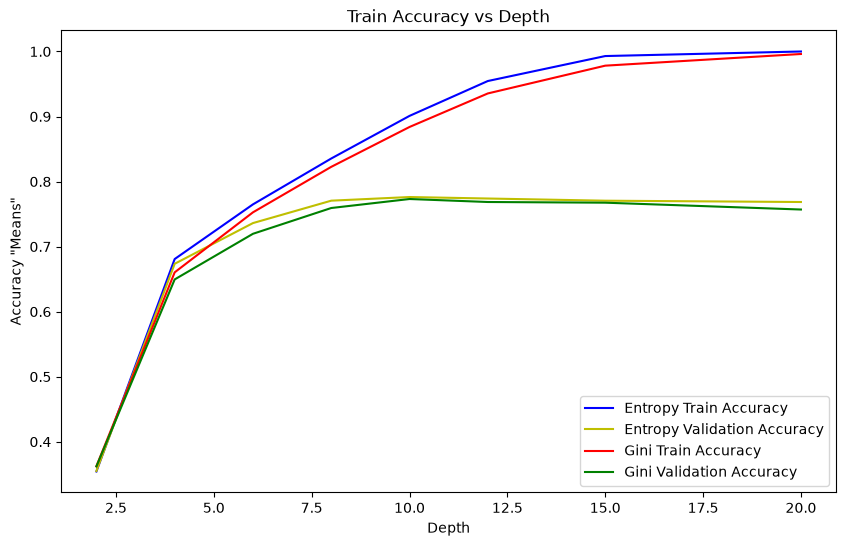

In [15]:
### part 1b - train and validation accuracy vs. depth (one plot, both criteria)
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in entropyTrainAccStats], label='Entropy Train Accuracy', color='b')
ax.plot(depths, [i[0] for i in entropyValidationAccStats], label='Entropy Validation Accuracy', color='y')
ax.set_xlabel('Depth')
ax.set_ylabel('Accuracy "Means"')
ax.plot(depths, [i[0] for i in giniTrainAccStats], label='Gini Train Accuracy', color='r')
ax.plot(depths, [i[0] for i in giniValidationAccStats], label='Gini Validation Accuracy', color='g')
ax.legend(loc='lower right')
ax.set_title("Train Accuracy vs Depth")

C:\Users\epicb\AppData\Local\Temp\ipykernel_24068\1598938176.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


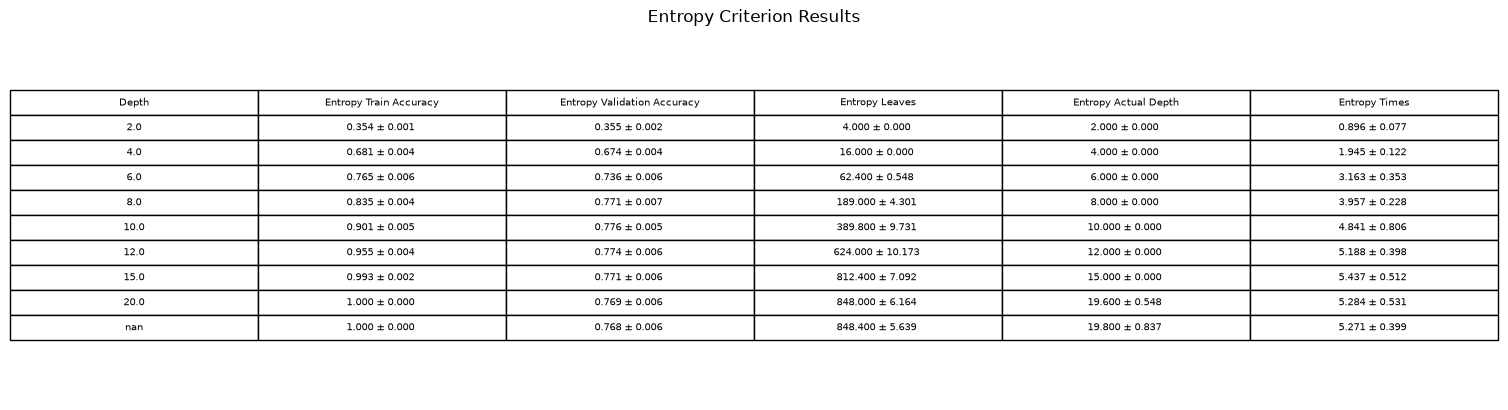

In [16]:
### part 1b - training time, number of leaves and actual depth & mean ± std over 5 random seeds or subsamples
table = pd.DataFrame({
    'Depth': depths,
    'Entropy Train Accuracy': combine(entropyTrainAccStats),
    'Entropy Validation Accuracy': combine(entropyValidationAccStats),
    'Entropy Leaves': combine(entropyLeaveStats),
    'Entropy Actual Depth': combine(entropyAcDepthStats),
    'Entropy Times': combine(entropyTimeStats)
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3, 1.5)
plt.title("Entropy Criterion Results")
plt.tight_layout()
plt.show()


C:\Users\epicb\AppData\Local\Temp\ipykernel_24068\3781357298.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


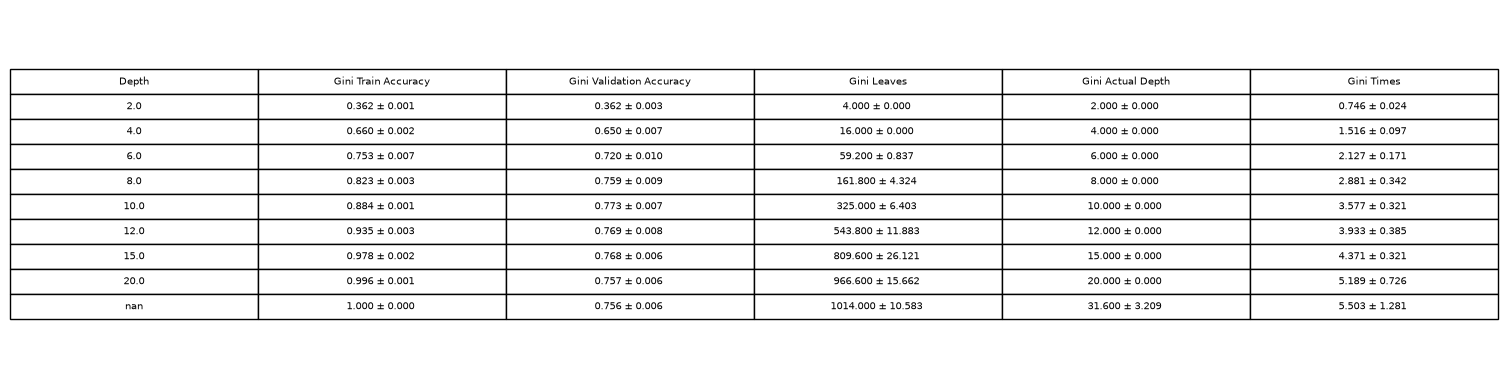

Text(0.5, 1.0, 'Gini Criterion Results')

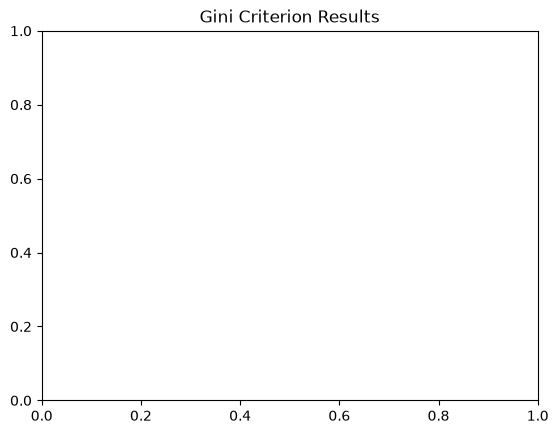

In [17]:
### part 1b - training time, number of leaves and actual depth & mean ± std over 5 random seeds or subsamples
table = pd.DataFrame({
    'Depth': depths,
    'Gini Train Accuracy': combine(giniTrainAccStats),
    'Gini Validation Accuracy': combine(giniValidationAccStats),
    'Gini Leaves': combine(giniLeaveStats),
    'Gini Actual Depth': combine(giniAcDepthStats),
    'Gini Times': combine(giniTimeStats)
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3, 1.5)
plt.tight_layout()
plt.show()
plt.title("Gini Criterion Results")

In [18]:
### part 1c pruning
import random

validationAccuracies = []
leafCounts = []
selectedAlphas = []
useAlphas = []

# compute the cost complexity path
for l in range(len(RANDOM_SEEDS)):
    tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l])
    path = tree.cost_complexity_pruning_path(xtrs[l], ytrs[l])
    selectedAlphas.extend(path.ccp_alphas)

# select say 20 values
# https://numpy.org/doc/stable/user/how-to-partition.html
indices = np.linspace(0, len(selectedAlphas) - 1, 20, dtype=int)
for i in indices:
    useAlphas.append(selectedAlphas[i])

# these will be the actual alpha values we use
useAlphas.sort()

# iterate through and calculate train and validationa accuracies
for l in range(len(RANDOM_SEEDS)):
    print(l)
    currValidationAccuracies = []
    currLeafCounts = []

    # try each alpha
    for i,alpha in enumerate(useAlphas):
        ccpTree = DecisionTreeClassifier(criterion='gini', ccp_alpha = alpha, random_state=RANDOM_SEEDS[l])
        ccpTree.fit(xtrs[l],ytrs[l])
        predict = ccpTree.predict(xvals[l])
        currValidationAccuracies.append(accuracy_score(predict, yvals[l]))
        currLeafCounts.append(ccpTree.get_n_leaves())
    validationAccuracies.append(currValidationAccuracies)
    leafCounts.append(currLeafCounts)

0
1
2
3
4


In [19]:
# get mean and std estimate, mean_std isn't necessary here
validationAccuracyMeans = np.mean(validationAccuracies, axis=0)
validationAccuracyStds = np.std(validationAccuracies, axis=0)
leafCountMeans = np.mean(leafCounts, axis=0)
leafCountStds = np.std(leafCounts, axis=0)

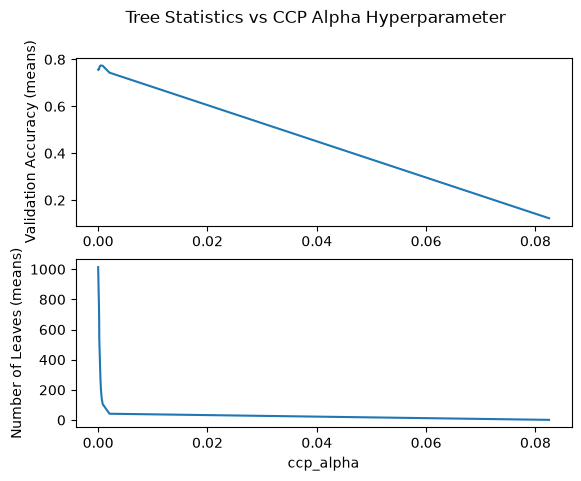

In [20]:
# P1c plot validation accuracy and leaft count vs alpha
fig, ax = plt.subplots(2, 1)

fig.suptitle("Tree Statistics vs CCP Alpha Hyperparameter")
ax[0].plot(useAlphas,validationAccuracyMeans)
ax[0].set_ylabel('Validation Accuracy (means)')

ax[1].plot(useAlphas, leafCountMeans)
ax[1].set_xlabel('ccp_alpha')
ax[1].set_ylabel('Number of Leaves (means)')

plt.show()

In [21]:
#https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
grid = GridSearchCV(
    DecisionTreeClassifier(
        criterion='gini',
        random_state=RANDOM_SEEDS[0]
    ),
    param_grid={'ccp_alpha': useAlphas},
    cv=5,
    scoring='accuracy',
)

grid.fit(xtr,ytr)
best = grid.best_params_["ccp_alpha"]

print("Optimal Alpha: {:.4f}".format(best))
print("Best Pruning Validation Accuracy {:.4f}".format(grid.best_estimator_.score(xval,yval)))

Optimal Alpha: 0.0006
Best Pruning Validation Accuracy 0.7672


In [22]:
### best depth was None
tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[0], max_depth=None)
tree.fit(xtr,ytr)
print("Best Depth-Limited Tree Validation Accuracy : {:.4f}".format(tree.score(xval, yval)))

Best Depth-Limited Tree Validation Accuracy : 0.7534


In [23]:
# part 1c, trying min_samples_leaf
### part 1c pruning
import random

mslTrees = []
mslValidationAccuracies = []
mslLeafCounts = []
minSamplesLeaf = [1,5,20,50]

# iterate through and calculate validation accuracies and leaf counts
for l in range(len(RANDOM_SEEDS)):
    print(l)
    currValidationAccuracies = []
    currLeafCounts = []
    currMslTrees = []
    for msl in minSamplesLeaf:
        mslTree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l], min_samples_leaf=msl)
        mslTree.fit(xtrs[l], ytrs[l])

        validationPredictions = mslTree.predict(xvals[l])
        currValidationAccuracies.append(accuracy_score(yvals[l], validationPredictions))

        currLeafCounts.append(mslTree.get_n_leaves())
        currMslTrees.append(mslTree)
    mslValidationAccuracies.append(currValidationAccuracies)
    mslLeafCounts.append(currLeafCounts)
    mslTrees.append(currMslTrees)

0
1
2
3
4


In [24]:
# part 1c - min samples leaf statistics
mslValidationAccuracyStats = calcStats(mslValidationAccuracies, sweep=minSamplesLeaf)
mslLeafStats = calcStats(mslLeafCounts, sweep=minSamplesLeaf)

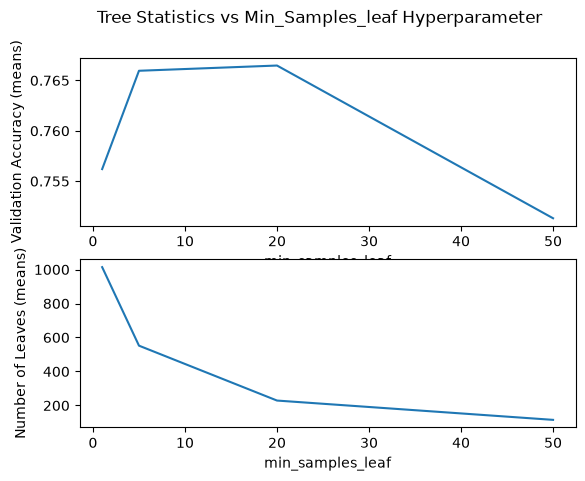

In [25]:
# P1c plot validation accuracy and leaft count vs min_samples_Leaf
fig, ax = plt.subplots(2, 1)
fig.suptitle("Tree Statistics vs Min_Samples_leaf Hyperparameter")
ax[0].plot(minSamplesLeaf,[i[0] for i in mslValidationAccuracyStats])
ax[0].set_xlabel('min_samples_leaf')
ax[0].set_ylabel('Validation Accuracy (means)')

ax[1].plot(minSamplesLeaf, [i[0] for i in mslLeafStats])
ax[1].set_xlabel('min_samples_leaf')
ax[1].set_ylabel('Number of Leaves (means)')

plt.show()

In [26]:
# we can see the best one clearly, but use this anyway to grab score easier
grid = GridSearchCV(
    DecisionTreeClassifier(
        criterion='gini',
        random_state=RANDOM_SEEDS[0]
    ),
    param_grid={'min_samples_leaf': minSamplesLeaf},
    cv=5,
    scoring='accuracy',
)

grid.fit(xtr,ytr)
best = grid.best_params_["min_samples_leaf"]

print("Optimal min_samples_leaf: {:.4f}".format(best))
print("Best min_samples_leaf Validation Accuracy {:.4f}".format(grid.best_estimator_.score(xval,yval)))

Optimal min_samples_leaf: 5.0000
Best min_samples_leaf Validation Accuracy 0.7636


In [9]:
# part 1d regression - get data
regX = californiaHousing.data
regy = californiaHousing.target

regxtrs,regxvals,regytrs,regyvals,regxtes,regytes = [],[],[],[],[],[]

for l in RANDOM_SEEDS:
    regxtr, regxte, regytr, regyte = train_test_split(regX,regy, test_size=0.2, random_state=l)
    regxtr,regxval, regytr,regyval = train_test_split(regxtr,regytr, test_size=0.2, random_state=l)
    regxtrs.append(regxtr)
    regytrs.append(regytr)
    regxvals.append(regxval)
    regyvals.append(regyval)
    regxtes.append(regxte)
    regytes.append(regyte)


In [28]:
### Part 1d regression
# done in a similar way to 1b
# i know the variables should be called error/errors not accuracy, but it would take a while to rename all
rmseTrees = []

rmseTrainMSEAccuracies = []
rmseTrainRMSEAccuracies = []
rmseTrainMAEAccuracies = []

rmseValidationMSEAccuracies = []
rmseValidationRMSEAccuracies = []
rmseValidationMAEAccuracies = []

maeTrees = []

maeTrainMSEAccuracies = []
maeTrainRMSEAccuracies = []
maeTrainMAEAccuracies = []

maeValidationMSEAccuracies = []
maeValidationRMSEAccuracies = []
maeValidationMAEAccuracies = []

friedTrees = []

friedTrainMSEAccuracies = []
friedTrainRMSEAccuracies = []
friedTrainMAEAccuracies = []

friedValidationMSEAccuracies = []
friedValidationRMSEAccuracies = []
friedValidationMAEAccuracies = []

depths = [2,4,6,8,10]

for l in range(len(RANDOM_SEEDS)):
    print(l)
    currRmseTrees = []

    currRmseTrainMSEAccuracies = []
    currRmseTrainRMSEAccuracies = []
    currRmseTrainMAEAccuracies = []

    currRmseValidationMSEAccuracies = []
    currRmseValidationRMSEAccuracies = []
    currRmseValidationMAEAccuracies = []

    currMaeTrees = []

    currMaeTrainMSEAccuracies = []
    currMaeTrainRMSEAccuracies = []
    currMaeTrainMAEAccuracies = []

    currMaeValidationMSEAccuracies = []
    currMaeValidationRMSEAccuracies = []
    currMaeValidationMAEAccuracies = []

    currFriedTrees = []

    currFriedTrainMSEAccuracies = []
    currFriedTrainRMSEAccuracies = []
    currFriedTrainMAEAccuracies = []

    currFriedValidationMSEAccuracies = []
    currFriedValidationRMSEAccuracies = []
    currFriedValidationMAEAccuracies = []

    for depth in depths:
        print(depth)
        # create and fit tree
        rmseTree = DecisionTreeRegressor(criterion='squared_error', random_state=RANDOM_SEEDS[l], max_depth=depth)
        rmseTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        rmseTreePredictions = rmseTree.predict(regxtrs[l])
        rmseTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], rmseTreePredictions)
        rmseTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], rmseTreePredictions)
        rmseTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], rmseTreePredictions)

        # validation accuracy
        rmseTreePredictions = rmseTree.predict(regxvals[l])
        rmseTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], rmseTreePredictions)
        rmseTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], rmseTreePredictions)
        rmseTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], rmseTreePredictions)

        # update lists
        currRmseTrees.append(rmseTree)

        currRmseTrainMSEAccuracies.append(rmseTreeTrainMSEAccuracy)
        currRmseTrainRMSEAccuracies.append(rmseTreeTrainRMSEAccuracy)
        currRmseTrainMAEAccuracies.append(rmseTreeTrainMAEAccuracy)

        currRmseValidationMSEAccuracies.append(rmseTreeValidationMSEAccuracy)
        currRmseValidationRMSEAccuracies.append(rmseTreeValidationRMSEAccuracy)
        currRmseValidationMAEAccuracies.append(rmseTreeValidationMAEAccuracy)

    print("RMSE Done")

    for depth in depths:
        print(depth)
        # create and fit tree
        maeTree = DecisionTreeRegressor(criterion='absolute_error', random_state=RANDOM_SEEDS[l], max_depth=depth)
        maeTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        maeTreePredictions = maeTree.predict(regxtrs[l])
        maeTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], maeTreePredictions)
        maeTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], maeTreePredictions)
        maeTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], maeTreePredictions)

        # validation accuracy
        maeTreePredictions = maeTree.predict(regxvals[l])
        maeTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], maeTreePredictions)
        maeTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], maeTreePredictions)
        maeTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], maeTreePredictions)

        # update lists
        currMaeTrees.append(maeTree)

        currMaeTrainMSEAccuracies.append(maeTreeTrainMSEAccuracy)
        currMaeTrainRMSEAccuracies.append(maeTreeTrainRMSEAccuracy)
        currMaeTrainMAEAccuracies.append(maeTreeTrainMAEAccuracy)

        currMaeValidationMSEAccuracies.append(maeTreeValidationMSEAccuracy)
        currMaeValidationRMSEAccuracies.append(maeTreeValidationRMSEAccuracy)
        currMaeValidationMAEAccuracies.append(maeTreeValidationMAEAccuracy)

    print("MAE Done")

    for depth in depths:
        print(depth)
        # create and fit tree
        friedTree = DecisionTreeRegressor(criterion='friedman_mse', random_state=RANDOM_SEEDS[l], max_depth=depth)
        friedTree.fit(regxtrs[l], regytrs[l])

        # training accuracy
        friedTreePredictions = friedTree.predict(regxtrs[l])
        friedTreeTrainMSEAccuracy = mean_squared_error(regytrs[l], friedTreePredictions)
        friedTreeTrainRMSEAccuracy = root_mean_squared_error(regytrs[l], friedTreePredictions)
        friedTreeTrainMAEAccuracy = mean_absolute_error(regytrs[l], friedTreePredictions)

        # validation accuracy
        friedTreePredictions = friedTree.predict(regxvals[l])
        friedTreeValidationMSEAccuracy = mean_squared_error(regyvals[l], friedTreePredictions)
        friedTreeValidationRMSEAccuracy = root_mean_squared_error(regyvals[l], friedTreePredictions)
        friedTreeValidationMAEAccuracy = mean_absolute_error(regyvals[l], friedTreePredictions)

        # update lists
        currFriedTrees.append(friedTree)

        currFriedTrainMSEAccuracies.append(friedTreeTrainMSEAccuracy)
        currFriedTrainRMSEAccuracies.append(friedTreeTrainRMSEAccuracy)
        currFriedTrainMAEAccuracies.append(friedTreeTrainMAEAccuracy)

        currFriedValidationMSEAccuracies.append(friedTreeValidationMSEAccuracy)
        currFriedValidationRMSEAccuracies.append(friedTreeValidationRMSEAccuracy)
        currFriedValidationMAEAccuracies.append(friedTreeValidationMAEAccuracy)

    print("Fried Done")

    rmseTrees.append(currRmseTrees)

    rmseTrainMSEAccuracies.append(currRmseTrainMSEAccuracies)
    rmseTrainRMSEAccuracies.append(currRmseTrainRMSEAccuracies)
    rmseTrainMAEAccuracies.append(currRmseTrainMAEAccuracies)

    rmseValidationMSEAccuracies.append(currRmseValidationMSEAccuracies)
    rmseValidationRMSEAccuracies.append(currRmseValidationRMSEAccuracies)
    rmseValidationMAEAccuracies.append(currRmseValidationMAEAccuracies)

    maeTrees.append(currMaeTrees)

    maeTrainMSEAccuracies.append(currMaeTrainMSEAccuracies)
    maeTrainRMSEAccuracies.append(currMaeTrainRMSEAccuracies)
    maeTrainMAEAccuracies.append(currMaeTrainMAEAccuracies)

    maeValidationMSEAccuracies.append(currMaeValidationMSEAccuracies)
    maeValidationRMSEAccuracies.append(currMaeValidationRMSEAccuracies)
    maeValidationMAEAccuracies.append(currMaeValidationMAEAccuracies)

    friedTrees.append(currFriedTrees)

    friedTrainMSEAccuracies.append(currFriedTrainMSEAccuracies)
    friedTrainRMSEAccuracies.append(currFriedTrainRMSEAccuracies)
    friedTrainMAEAccuracies.append(currFriedTrainMAEAccuracies)

    friedValidationMSEAccuracies.append(currFriedValidationMSEAccuracies)
    friedValidationRMSEAccuracies.append(currFriedValidationRMSEAccuracies)
    friedValidationMAEAccuracies.append(currFriedValidationMAEAccuracies)

0
2
4
6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.w

10
Fried Done
1
2
4


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(


6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.w

10
Fried Done
2
2
4


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(


6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.w

10
Fried Done
3
2
4


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(


6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.w

10
Fried Done
4
2
4


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(


6
8
10
RMSE Done
2
4
6
8
10
MAE Done
2
4
6
8


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(
c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.w

10
Fried Done


c:\Users\epicb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\tree\_classes.py:1347: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warnings.warn(


In [29]:
# calc stats similarly again
rmseTrainMSEAccuracyStats = calcStats(rmseTrainMSEAccuracies, sweep=depths)
rmseTrainRMSEAccuracyStats = calcStats(rmseTrainRMSEAccuracies, sweep=depths)
rmseTrainMAEAccuracyStats = calcStats(rmseTrainMAEAccuracies, sweep=depths)

rmseValidationMSEAccuracyStats = calcStats(rmseValidationMSEAccuracies, sweep=depths)
rmseValidationRMSEAccuracyStats = calcStats(rmseValidationRMSEAccuracies, sweep=depths)
rmseValidationMAEAccuracyStats = calcStats(rmseValidationMAEAccuracies, sweep=depths)

maeTrainMSEAccuracyStats = calcStats(maeTrainMSEAccuracies, sweep=depths)
maeTrainRMSEAccuracyStats = calcStats(maeTrainRMSEAccuracies, sweep=depths)
maeTrainMAEAccuracyStats = calcStats(maeTrainMAEAccuracies, sweep=depths)

maeValidationMSEAccuracyStats = calcStats(maeValidationMSEAccuracies, sweep=depths)
maeValidationRMSEAccuracyStats = calcStats(maeValidationRMSEAccuracies, sweep=depths)
maeValidationMAEAccuracyStats = calcStats(maeValidationMAEAccuracies, sweep=depths)

friedTrainMSEAccuracyStats = calcStats(friedTrainMSEAccuracies, sweep=depths)
friedTrainRMSEAccuracyStats = calcStats(friedTrainRMSEAccuracies, sweep=depths)
friedTrainMAEAccuracyStats = calcStats(friedTrainMAEAccuracies, sweep=depths)

friedValidationMSEAccuracyStats = calcStats(friedValidationMSEAccuracies, sweep=depths)
friedValidationRMSEAccuracyStats = calcStats(friedValidationRMSEAccuracies, sweep=depths)
friedValidationMAEAccuracyStats = calcStats(friedValidationMAEAccuracies, sweep=depths)

C:\Users\epicb\AppData\Local\Temp\ipykernel_24068\1847463415.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


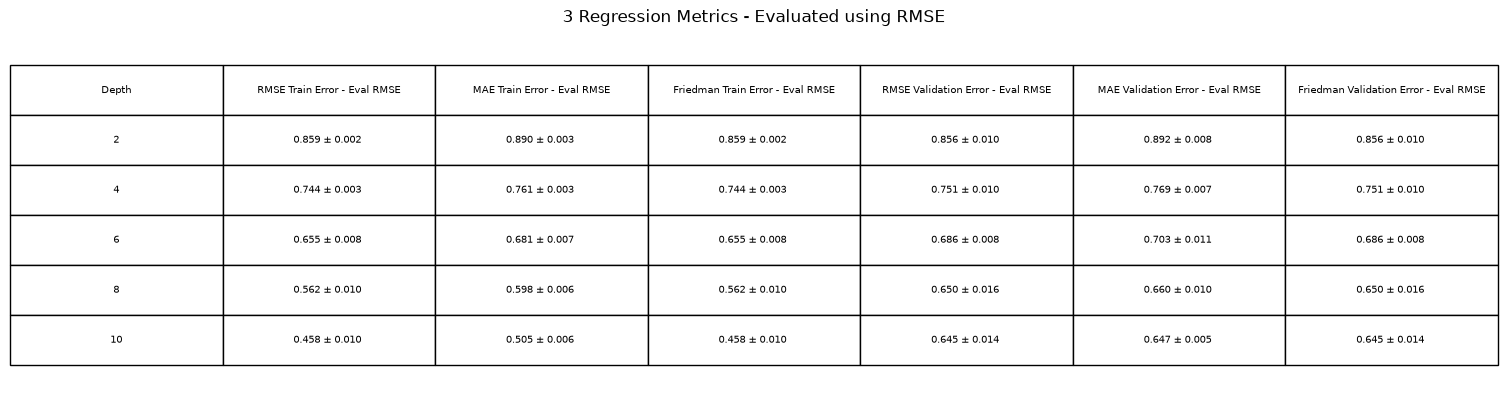

In [30]:
# part 1d plot rmse eval
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval RMSE' : combine(rmseTrainRMSEAccuracyStats),
    'MAE Train Error - Eval RMSE': combine(maeTrainRMSEAccuracyStats),
    'Friedman Train Error - Eval RMSE' : combine(friedTrainRMSEAccuracyStats),
    'RMSE Validation Error - Eval RMSE' : combine(rmseValidationRMSEAccuracyStats),
    'MAE Validation Error - Eval RMSE': combine(maeValidationRMSEAccuracyStats),
    'Friedman Validation Error - Eval RMSE' : combine(friedValidationRMSEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using RMSE")
plt.tight_layout()
plt.show()

C:\Users\epicb\AppData\Local\Temp\ipykernel_24068\3409220309.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


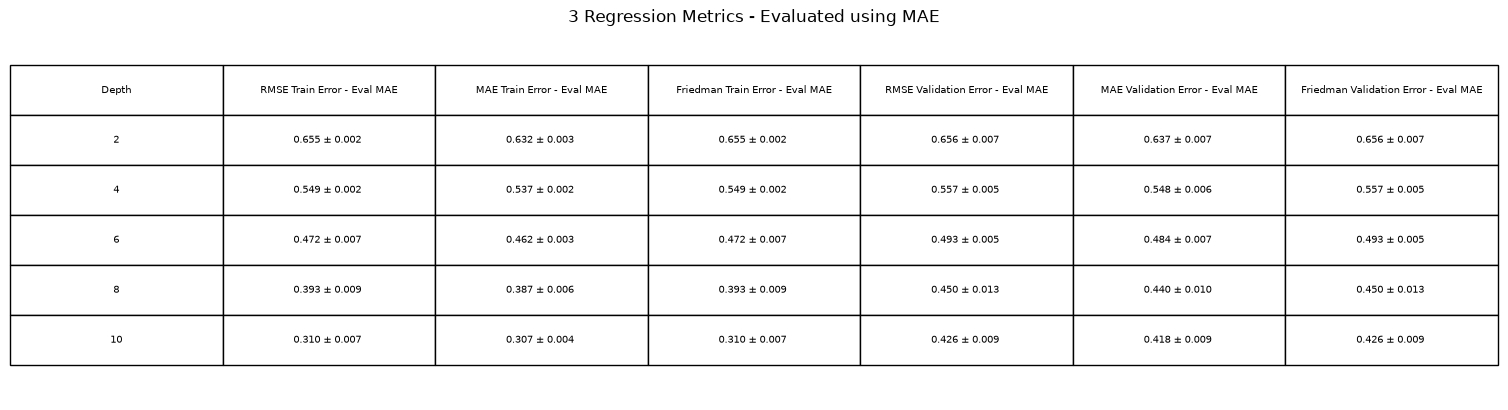

In [31]:
# part 1d plot mae eval
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval MAE' : combine(rmseTrainMAEAccuracyStats),
    'MAE Train Error - Eval MAE': combine(maeTrainMAEAccuracyStats),
    'Friedman Train Error - Eval MAE' : combine(friedTrainMAEAccuracyStats),
    'RMSE Validation Error - Eval MAE' : combine(rmseValidationMAEAccuracyStats),
    'MAE Validation Error - Eval MAE': combine(maeValidationMAEAccuracyStats),
    'Friedman Validation Error - Eval MAE' : combine(friedValidationMAEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using MAE")
plt.tight_layout()
plt.show()

C:\Users\epicb\AppData\Local\Temp\ipykernel_24068\3769093511.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


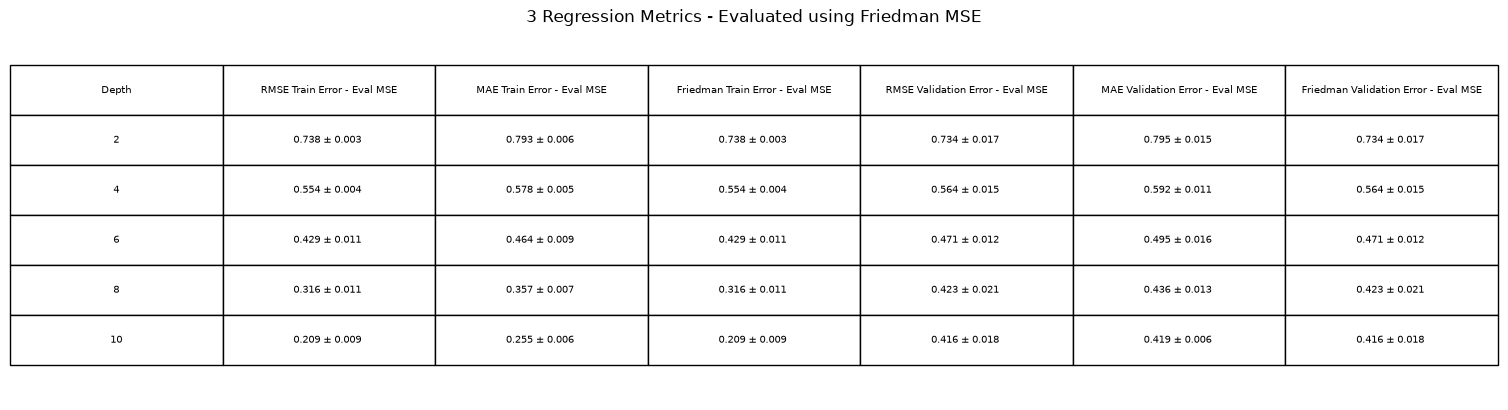

In [32]:
# part 1d plot fried eval
table = pd.DataFrame({
    'Depth': depths,
    'RMSE Train Error - Eval MSE' : combine(rmseTrainMSEAccuracyStats),
    'MAE Train Error - Eval MSE': combine(maeTrainMSEAccuracyStats),
    'Friedman Train Error - Eval MSE' : combine(friedTrainMSEAccuracyStats),
    'RMSE Validation Error - Eval MSE' : combine(rmseValidationMSEAccuracyStats),
    'MAE Validation Error - Eval MSE': combine(maeValidationMSEAccuracyStats),
    'Friedman Validation Error - Eval MSE' : combine(friedValidationMSEAccuracyStats),
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3,3)
axtable.set
plt.title("3 Regression Metrics - Evaluated using Friedman MSE")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, '3 Regression metrics - Evaluated using RMSE')

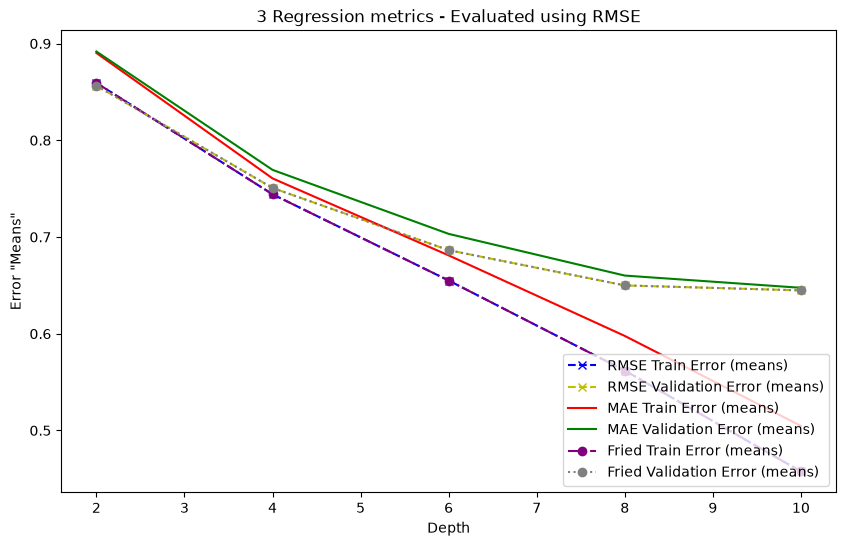

In [33]:
# visualize it all on RMSE
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in rmseTrainRMSEAccuracyStats], label='RMSE Train Error (means)', color='b', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in rmseValidationRMSEAccuracyStats], label='RMSE Validation Error (means)', color='y', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in maeTrainRMSEAccuracyStats], label='MAE Train Error (means)', color='r')
ax.plot(depths, [i[0] for i in maeValidationRMSEAccuracyStats], label='MAE Validation Error (means)', color='g')
ax.plot(depths, [i[0] for i in friedTrainRMSEAccuracyStats], label='Fried Train Error (means)', color='purple',linestyle='-.', marker='o')
ax.plot(depths, [i[0] for i in friedValidationRMSEAccuracyStats], label='Fried Validation Error (means)', color='grey',linestyle=':', marker='o')
ax.set_xlabel('Depth')
ax.set_ylabel('Error "Means"')
ax.legend(loc='lower right')
ax.set_title("3 Regression metrics - Evaluated using RMSE")

Text(0.5, 1.0, '3 Regression metrics - Evaluated using MAE')

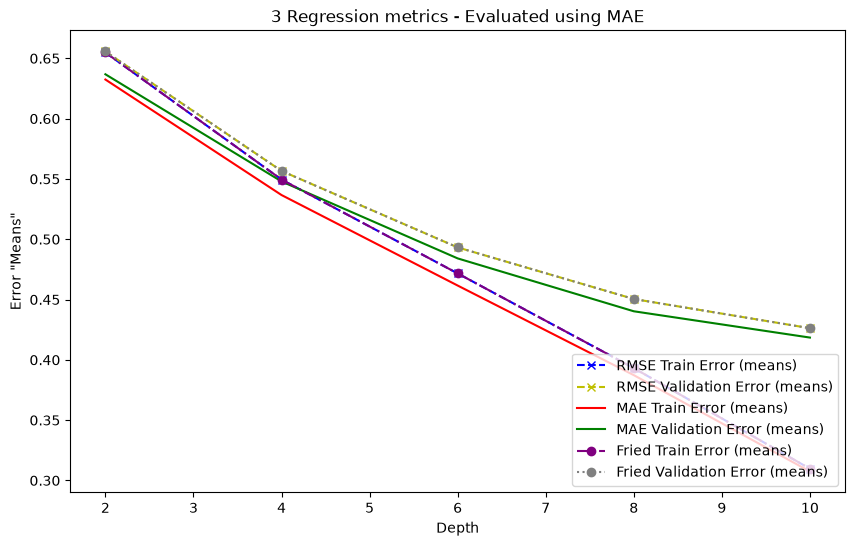

In [34]:
# visualize it all on MAE
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in rmseTrainMAEAccuracyStats], label='RMSE Train Error (means)', color='b', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in rmseValidationMAEAccuracyStats], label='RMSE Validation Error (means)', color='y', linestyle='--', marker='x')
ax.plot(depths, [i[0] for i in maeTrainMAEAccuracyStats], label='MAE Train Error (means)', color='r')
ax.plot(depths, [i[0] for i in maeValidationMAEAccuracyStats], label='MAE Validation Error (means)', color='g')
ax.plot(depths, [i[0] for i in friedTrainMAEAccuracyStats], label='Fried Train Error (means)', color='purple',linestyle='-.', marker='o')
ax.plot(depths, [i[0] for i in friedValidationMAEAccuracyStats], label='Fried Validation Error (means)', color='grey',linestyle=':', marker='o')
ax.set_xlabel('Depth')
ax.set_ylabel('Error "Means"')
ax.legend(loc='lower right')
ax.set_title("3 Regression metrics - Evaluated using MAE")

In [35]:
# part 1d get best tree
bestTree = None
bestRMSE = float('inf')
seed = None

for trees in [rmseTrees, maeTrees, friedTrees]:
    for l in range(len(RANDOM_SEEDS)):
        for tree in trees[l]:
            preds = tree.predict(regxvals[l])
            score = root_mean_squared_error(regyvals[l], preds)

            if score <bestRMSE:
                bestRMSE = score
                bestTree = tree
                seed = l

print("Best Validation RMSE: {:.3f}".format(bestRMSE))

Best Validation RMSE: 0.624


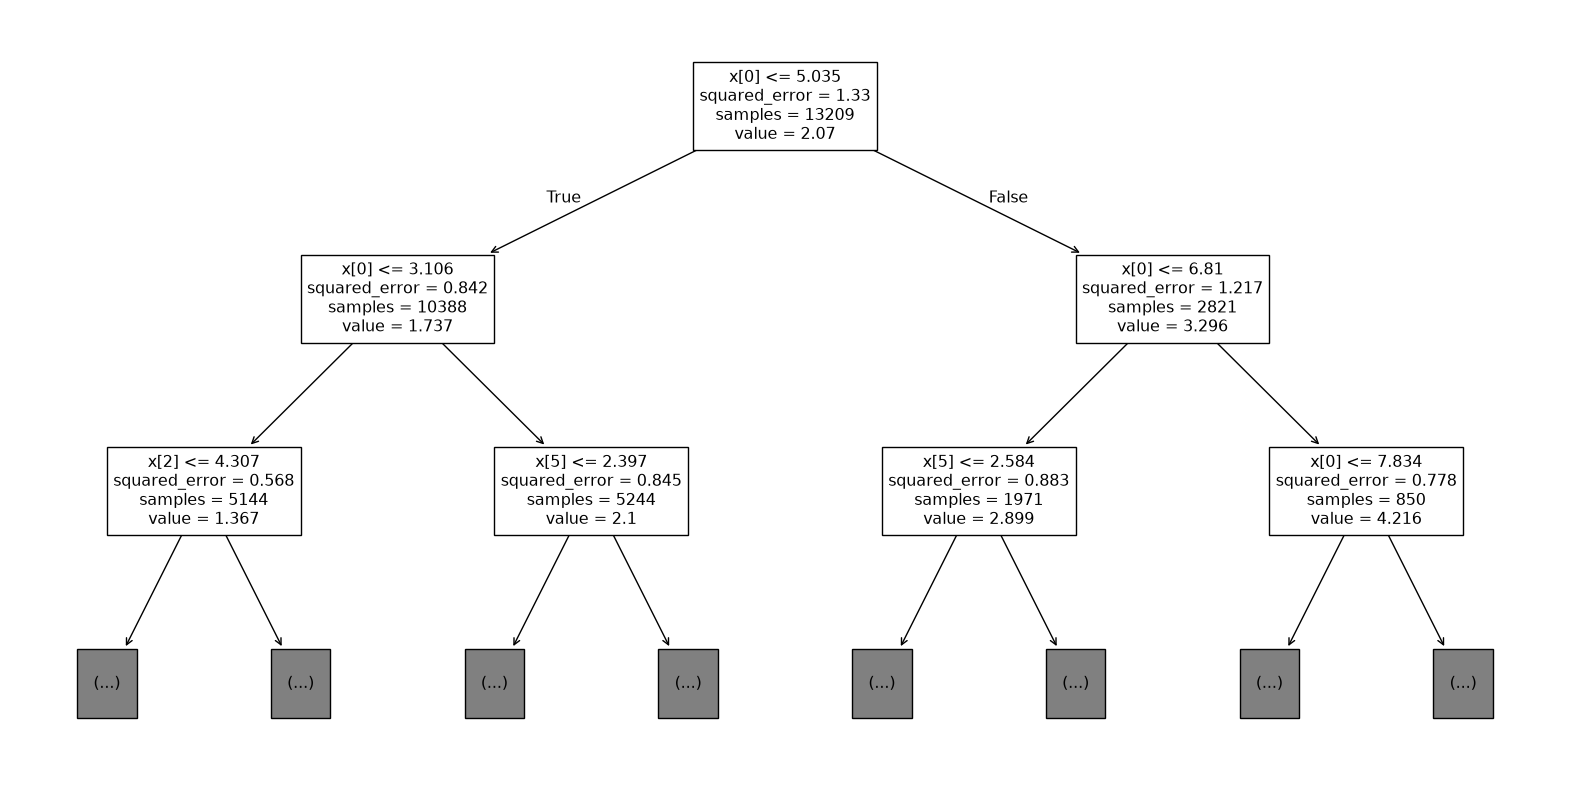

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [36]:
# part 1d look at the top three levels of the best tree
plt.figure(figsize=(20,10))

plot_tree(
    bestTree, 
    max_depth=2,
)
plt.show()

print(fetch_california_housing().feature_names)

Text(0.5, 1.0, 'Prediced Price vs Median Income - Showing Piecewise')

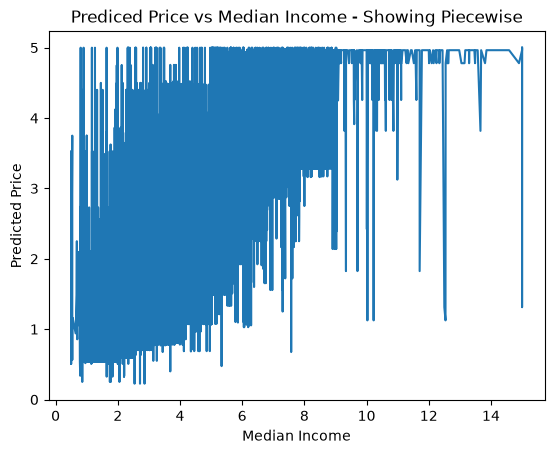

In [37]:
# part 1d visualize step function prediction
MedInc = regX[:,0]

# best tree preds
preds = bestTree.predict(regX)

# sort feature
indx = np.argsort(MedInc)

# plot
plt.figure()
plt.plot(MedInc[indx], preds[indx])
plt.xlabel("Median Income")
plt.ylabel("Predicted Price")
plt.title("Prediced Price vs Median Income - Showing Piecewise")


In [38]:
### PART 2 

pastingModelSizes = []
baggingModelSizes = []
ranSubModelSizes = []
ranPatchModelSizes = []

pastingTrTimes = []
baggingTrTimes = []
ranSubTrTimes = []
ranPatchTrTimes = []

pastingPrTimes = []
baggingPrTimes = []
ranSubPrTimes = []
ranPatchPrTimes = []

pastingValidationAccuracies = []
baggingValidationAccuracies = []
ranSubValidationAccuracies = []
ranPatchValidationAccuracies = []

pastingTrainAccuracies = []
baggingTrainAccuracies = []
ranSubTrainAccuracies = []
ranPatchTrainAccuracies = []

n = 15000 #total number of predictions per train and val test set

sweepRows = [0.1,0.3,0.5,0.7,1.0]

for l in range(len(RANDOM_SEEDS)):
    print(l)

    currPastingModelSizes = []
    currBaggingModelSizes = []
    currRanSubModelSizes = []
    currRanPatchModelSizes = []

    currPastingTrTimes = []
    currBaggingTrTimes = []
    currRanSubTrTimes = []
    currRanPatchTrTimes = []

    currPastingPrTimes = []
    currBaggingPrTimes = []
    currRanSubPrTimes = []
    currRanPatchPrTimes = []

    currPastingValidationAccuracies = []
    currBaggingValidationAccuracies = []
    currRanSubValidationAccuracies = []
    currRanPatchValidationAccuracies = []

    currPastingTrainAccuracies = []
    currBaggingTrainAccuracies = []
    currRanSubTrainAccuracies = []
    currRanPatchTrainAccuracies = []

    #pasting
    for frac in sweepRows:
        stTr = time.time()
        
        pasting = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        pasting.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = pasting.predict(xtrs[l])
        currPastingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = pasting.predict(xvals[l])
        currPastingValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        currPastingTrTimes.append(endTr-stTr)
        currPastingPrTimes.append((endPr-stPr)*1000*1000/n)
        currPastingModelSizes.append(sum(tree.tree_.node_count for tree in pasting.estimators_))

    #bagging
    for frac in sweepRows:
        stTr = time.time()    
        
        bagging = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=True,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        bagging.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = bagging.predict(xtrs[l])
        currBaggingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = bagging.predict(xvals[l])
        currBaggingValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        currBaggingTrTimes.append(endTr-stTr)
        currBaggingPrTimes.append((endPr-stPr)*1000*1000/n)
        currBaggingModelSizes.append(sum(tree.tree_.node_count for tree in bagging.estimators_))

    #random subspaces
    for frac in sweepRows:
        stTr = time.time()
        
        ranSub = BaggingClassifier(
            estimator=DecisionTreeClassifier(),
            n_estimators=100,
            max_samples=1.0,
            max_features=frac,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        ranSub.fit(xtrs[l], ytrs[l])
        endTr = time.time()

        stPr = time.time()
        preds = ranSub.predict(xtrs[l])
        currRanSubTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = ranSub.predict(xvals[l])
        currRanSubValidationAccuracies.append(accuracy_score(yvals[l], preds))
        endPr = time.time()
        currRanSubTrTimes.append(endTr-stTr)
        currRanSubPrTimes.append((endPr-stPr)*1000*1000/n)
        currRanSubModelSizes.append(sum(tree.tree_.node_count for tree in ranSub.estimators_))

    #random patches
    for colfrac in sweepRows:
        currColTrainAccuracies = []
        currColValidationAccuracies = []
        currColTrTimes = []
        currColPrTimes = []
        currColModelSizes = []

        for rowfrac in sweepRows:
            stTr = time.time()

            ranPatch = BaggingClassifier(
                estimator=DecisionTreeClassifier(),
                n_estimators=100,
                max_samples=rowfrac,
                max_features=colfrac,
                bootstrap=False,
                bootstrap_features=False,
                random_state=RANDOM_SEEDS[l],
                n_jobs=-1
            )

            ranPatch.fit(xtrs[l], ytrs[l])
            endTr = time.time()

            stPr = time.time()
            preds = ranPatch.predict(xtrs[l])
            currColTrainAccuracies.append(accuracy_score(ytrs[l], preds))

            preds = ranPatch.predict(xvals[l])
            currColValidationAccuracies.append(accuracy_score(yvals[l], preds))
            endPr = time.time()

            currColTrTimes.append(endTr - stTr)
            currColPrTimes.append((endPr-stPr)*1000*1000/n)
            currColModelSizes.append(sum(tree.tree_.node_count for tree in ranPatch.estimators_))

        currRanPatchTrainAccuracies.append(currColTrainAccuracies)
        currRanPatchValidationAccuracies.append(currColValidationAccuracies)
        currRanPatchTrTimes.append(currColTrTimes)
        currRanPatchPrTimes.append(currColPrTimes)
        currRanPatchModelSizes.append(currColModelSizes)

    pastingModelSizes.append(currPastingModelSizes)
    baggingModelSizes.append(currBaggingModelSizes)
    ranSubModelSizes.append(currRanSubModelSizes)
    ranPatchModelSizes.append(currRanPatchModelSizes)

    pastingTrTimes.append(currPastingTrTimes)
    baggingTrTimes.append(currBaggingTrTimes)
    ranSubTrTimes.append(currRanSubTrTimes)
    ranPatchTrTimes.append(currRanPatchTrTimes)

    pastingPrTimes.append(currPastingPrTimes)
    baggingPrTimes.append(currBaggingPrTimes)
    ranSubPrTimes.append(currRanSubPrTimes)
    ranPatchPrTimes.append(currRanPatchPrTimes)

    pastingValidationAccuracies.append(currPastingValidationAccuracies)
    baggingValidationAccuracies.append(currBaggingValidationAccuracies)
    ranSubValidationAccuracies.append(currRanSubValidationAccuracies)
    ranPatchValidationAccuracies.append(currRanPatchValidationAccuracies)

    pastingTrainAccuracies.append(currPastingTrainAccuracies)
    baggingTrainAccuracies.append(currBaggingTrainAccuracies)
    ranSubTrainAccuracies.append(currRanSubTrainAccuracies)
    ranPatchTrainAccuracies.append(currRanPatchTrainAccuracies)
    

0


KeyboardInterrupt: 

In [ ]:
# helps calculate the random patch stats
def calcRanPatchStats(vals):
    vals = np.array(vals)
    #[seeds][columns][rows]
    # average across columns w.r.t row fraction
    rowAverages = np.mean(vals, axis=1)
    rowStats = calcStats(rowAverages, sweep=None)

    # average across rows w.r.t column fraction
    colAverages = np.mean(vals, axis=2)
    colStats = calcStats(colAverages, sweep=None)

    return rowStats, colStats

In [ ]:
# part 2a - calc stats
pastingModelSizeStats = calcStats(pastingModelSizes, sweep=sweepRows)
baggingModelSizeStats = calcStats(baggingModelSizes, sweep=sweepRows)
ranSubModelSizeStats = calcStats(ranSubModelSizes, sweep=sweepRows)
ranPatchModelSizeRowStats, ranPatchModelSizeColStats = calcRanPatchStats(ranPatchModelSizes)

pastingTrTimeStats = calcStats(pastingTrTimes, sweep=sweepRows)
baggingTrTimeStats = calcStats(baggingTrTimes, sweep=sweepRows)
ranSubTrTimeStats = calcStats(ranSubTrTimes, sweep=sweepRows)
ranPatchTrTimeRowStats, ranPatchTrTimeColStats = calcRanPatchStats(ranPatchTrTimes)

pastingPrTimeStats = calcStats(pastingPrTimes, sweep=sweepRows)
baggingPrTimeStats = calcStats(baggingPrTimes, sweep=sweepRows)
ranSubPrTimeStats = calcStats(ranSubPrTimes, sweep=sweepRows)
ranPatchPrTimeRowStats, ranPatchPrTimeColStats = calcRanPatchStats(ranPatchPrTimes)

pastingValidationAccuracyStats = calcStats(pastingValidationAccuracies, sweep=sweepRows)
baggingValidationAccuracyStats = calcStats(baggingValidationAccuracies, sweep=sweepRows)
ranSubValidationAccuracyStats = calcStats(ranSubValidationAccuracies, sweep=sweepRows)
ranPatchValidationAccuracyRowStats, ranPatchValidationAccuracyColStats = calcRanPatchStats(ranPatchValidationAccuracies)

pastingTrainAccuracyStats = calcStats(pastingTrainAccuracies, sweep=sweepRows)
baggingTrainAccuracyStats = calcStats(baggingTrainAccuracies, sweep=sweepRows)
ranSubTrainAccuracyStats = calcStats(ranSubTrainAccuracies, sweep=sweepRows)
ranPatchTrainAccuracyRowStats, ranPatchTrainAccuracyColStats = calcRanPatchStats(ranPatchTrainAccuracies)

C:\Users\jafer\AppData\Local\Temp\ipykernel_21936\3572787604.py:18: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


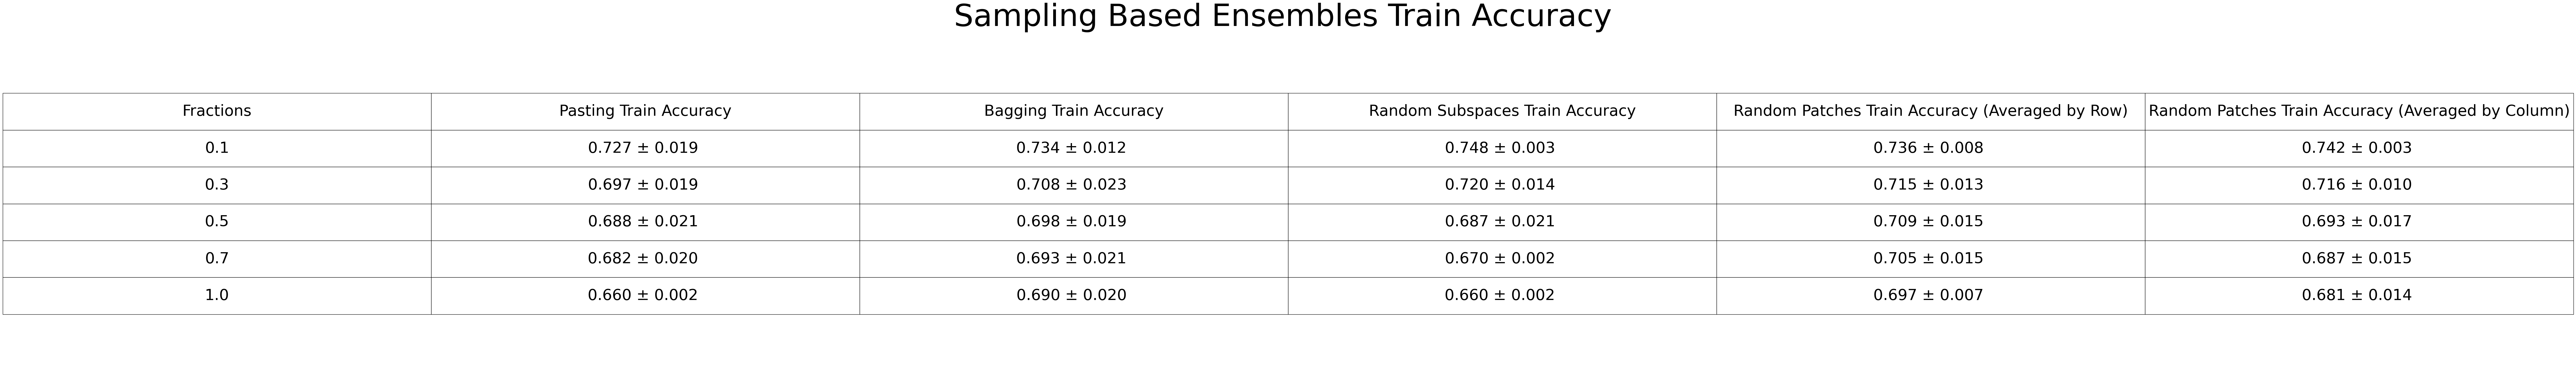

In [ ]:
# part2a - show stats as table
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Train Accuracy' : combine(pastingTrainAccuracyStats),
    'Bagging Train Accuracy': combine(baggingTrainAccuracyStats),
    'Random Subspaces Train Accuracy': combine(ranSubTrainAccuracyStats),
    'Random Patches Train Accuracy (Averaged by Row)': combine(ranPatchTrainAccuracyRowStats),
    'Random Patches Train Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(15,15))
fig.suptitle("Sampling Based Ensembles Train Accuracy", fontsize=80)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(40)
axtable.scale(8,8)
axtable.set
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_21936\3833306293.py:18: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


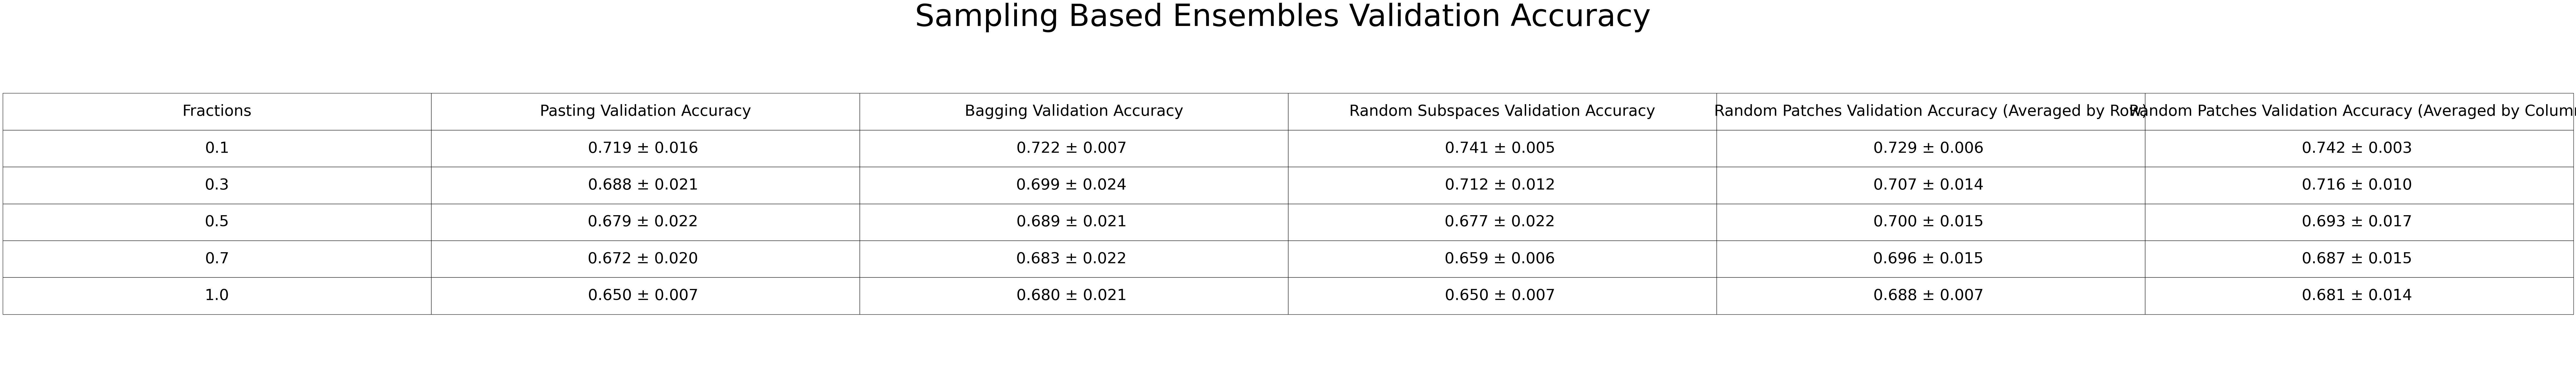

In [ ]:
# part2a - show stats as table
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Validation Accuracy' : combine(pastingValidationAccuracyStats),
    'Bagging Validation Accuracy': combine(baggingValidationAccuracyStats),
    'Random Subspaces Validation Accuracy': combine(ranSubValidationAccuracyStats),
    'Random Patches Validation Accuracy (Averaged by Row)': combine(ranPatchValidationAccuracyRowStats),
    'Random Patches Validation Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(15,15))
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(40)
axtable.scale(8,8)
axtable.set
fig.suptitle("Sampling Based Ensembles Validation Accuracy", fontsize=80)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Random Patches')

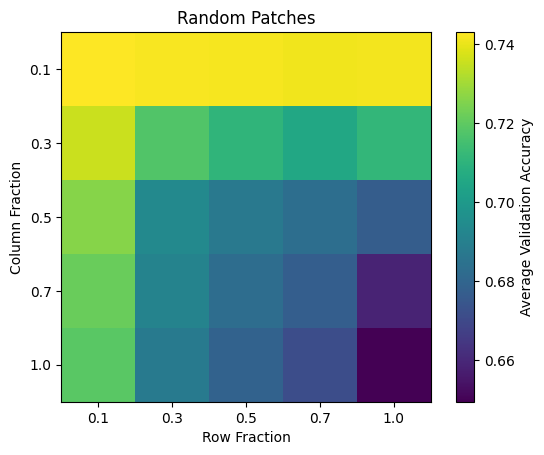

In [ ]:
# part2a - show heatmap
hm = np.mean(ranPatchValidationAccuracies, axis = 0)

fig,ax = plt.subplots()
im = ax.imshow(hm, cmap="viridis")
fig.colorbar(im,ax=ax, label="Average Validation Accuracy")
ax.set_xticks(range(len(sweepRows)))
ax.set_yticks(range(len(sweepRows)))
ax.set_xticklabels(sweepRows)
ax.set_yticklabels(sweepRows)
ax.set_xlabel("Row Fraction")
ax.set_ylabel("Column Fraction")
ax.set_title("Random Patches")

In [ ]:
# part 2b plot validation accuracy vs number of trees for bagging
#bagging
treeNums = [1,25,50,100,200,300]
baggingValidationAccuracies = []
oobStats = []
for tn in treeNums: 
    print(tn)       
    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=tn,
        max_samples=0.5,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0],
        n_jobs=-1, # to compute faster
        oob_score=True
    )
    bagging.fit(xtrs[0], ytrs[0])
    preds = bagging.predict(xvals[0])
    baggingValidationAccuracies.append(accuracy_score(yvals[0], preds))
    oobStats.append(bagging.oob_score_)

1


KeyboardInterrupt: 

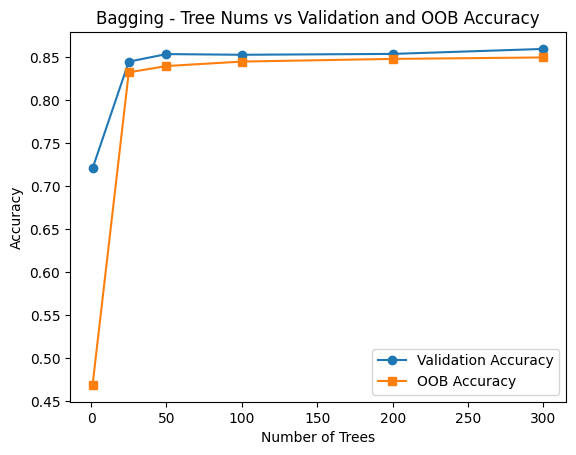

In [ ]:
# part 2b - plot
fig,ax = plt.subplots()
ax.plot(treeNums, baggingValidationAccuracies, marker='o', label='Validation Accuracy')
ax.plot(treeNums, oobStats, marker='s', label="OOB Accuracy")
ax.set_xlabel("Number of Trees")
ax.set_ylabel("Accuracy")
ax.set_title("Bagging - Tree Nums vs Validation and OOB Accuracy")
plt.legend()
plt.show()

In [ ]:
# part 2c
preds = {
    "pasting": [],
    "bagging": [],
    "ransub": [],
    "ranpatch": [],
    "unpruned": [],
    "depth4": []
}
for i in range(10):
    # get different bootstrap resamples each time
    xboot,yboot = resample(xtrs[0], ytrs[0], replace=True, random_state=RANDOM_SEEDS[0]+i)

    pasting = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50, #for faster computation, results diminish past this
        max_samples=0.5,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1 # to compute faster
    )
    pasting.fit(xboot,yboot)
    preds["pasting"].append(pasting.predict(xvals[0]))

    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        max_samples=0.5,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1 # to compute faster
    )
    bagging.fit(xboot,yboot)
    preds["bagging"].append(bagging.predict(xvals[0]))

    ranSub = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        max_samples=1.0,
        max_features=0.5,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1 # to compute faster
    )
    ranSub.fit(xboot,yboot)
    preds["ransub"].append(ranSub.predict(xvals[0]))

    ranPatch = BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        max_samples=0.5,
        max_features=0.5,
        bootstrap=False,
        bootstrap_features=False,
        random_state=RANDOM_SEEDS[0]+i,
        n_jobs=-1
    )
    ranPatch.fit(xboot,yboot)
    preds["ranpatch"].append(ranPatch.predict(xvals[0]))

    unpruned = DecisionTreeClassifier(
        random_state=RANDOM_SEEDS[0]+i
    )
    unpruned.fit(xboot, yboot)
    preds["unpruned"].append(unpruned.predict(xvals[0]))

    depth4 = DecisionTreeClassifier(
        max_depth=4,
        random_state=RANDOM_SEEDS[0]+i
    )
    depth4.fit(xboot, yboot)
    preds["depth4"].append(depth4.predict(xvals[0]))


In [ ]:
# part 2c compute disagreement rate
disagrees = []
errs = []

# iterate through each model
for model in preds.keys():
    predictions = np.array(preds[model])

    # compute majority
    majority = []
    for j in range(predictions.shape[1]):
        # return lists of the unique labels and their counts
        labels, counts = np.unique(predictions[:, j], return_counts=True)
        # the majority is the argmax
        majority.append(labels[np.argmax(counts)])

    majority = np.array(majority)

    # average the predictions that are not the majority
    disagree = np.mean(predictions != majority)

    # compare against true labels
    trueLabels = np.asarray(yvals[0])
    err = np.mean(majority != trueLabels)

    disagrees.append(disagree)
    errs.append(err)

    print("{}: Disagreement={:.4f}, Error={:.4f}".format(
        model, disagree, err
    ))

pasting: Disagreement=0.0647, Error=0.1462
bagging: Disagreement=0.0596, Error=0.1444
ransub: Disagreement=0.0616, Error=0.1384
ranpatch: Disagreement=0.0547, Error=0.1406
unpruned: Disagreement=0.1988, Error=0.1606
depth4: Disagreement=0.0811, Error=0.3260


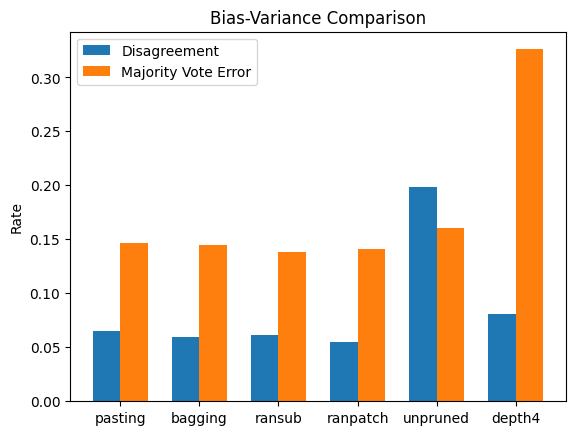

In [ ]:
#part 2c plot the comparison
# https://www.geeksforgeeks.org/python/plotting-multiple-bar-charts-using-matplotlib-in-python/
fig, ax = plt.subplots()
x = np.arange(len(preds))
width = 0.35

ax.bar(x - width/2, disagrees, width, label="Disagreement")
ax.bar(x + width/2, errs, width, label="Majority Vote Error")

ax.set_xticks(x)
ax.set_xticklabels(list(preds.keys()))
ax.set_ylabel("Rate")
ax.set_title("Bias-Variance Comparison")
ax.legend()

plt.show()

In [ ]:
# part 2d
pastingValidationAccuracies = []
baggingValidationAccuracies = []
ranSubValidationAccuracies = []
ranPatchValidationAccuracies = []

pastingTrainAccuracies = []
baggingTrainAccuracies = []
ranSubTrainAccuracies = []
ranPatchTrainAccuracies = []

sweepRows = [0.1,0.3,0.5,0.7,1.0]

for l in range(len(RANDOM_SEEDS)):
    print(l)

    currPastingValidationAccuracies = []
    currBaggingValidationAccuracies = []
    currRanSubValidationAccuracies = []
    currRanPatchValidationAccuracies = []

    currPastingTrainAccuracies = []
    currBaggingTrainAccuracies = []
    currRanSubTrainAccuracies = []
    currRanPatchTrainAccuracies = []

    #pasting
    for frac in sweepRows:
        pasting = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=4),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        pasting.fit(xtrs[l], ytrs[l])

        preds = pasting.predict(xtrs[l])
        currPastingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = pasting.predict(xvals[l])
        currPastingValidationAccuracies.append(accuracy_score(yvals[l], preds))

    #bagging
    for frac in sweepRows:
        bagging = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=4),
            n_estimators=100,
            max_samples=frac,
            max_features=1.0,
            bootstrap=True,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        bagging.fit(xtrs[l], ytrs[l])

        preds = bagging.predict(xtrs[l])
        currBaggingTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = bagging.predict(xvals[l])
        currBaggingValidationAccuracies.append(accuracy_score(yvals[l], preds))

    #random subspaces
    for frac in sweepRows:
        ranSub = BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=4),
            n_estimators=100,
            max_samples=1.0,
            max_features=frac,
            bootstrap=False,
            bootstrap_features=False,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        ranSub.fit(xtrs[l], ytrs[l])
       
        preds = ranSub.predict(xtrs[l])
        currRanSubTrainAccuracies.append(accuracy_score(ytrs[l], preds))

        preds = ranSub.predict(xvals[l])
        currRanSubValidationAccuracies.append(accuracy_score(yvals[l], preds))

    #random patches
    for colfrac in sweepRows:
        currColTrainAccuracies = []
        currColValidationAccuracies = []

        for rowfrac in sweepRows:
            ranPatch = BaggingClassifier(
                estimator=DecisionTreeClassifier(max_depth=4),
                n_estimators=100,
                max_samples=rowfrac,
                max_features=colfrac,
                bootstrap=False,
                bootstrap_features=False,
                random_state=RANDOM_SEEDS[l],
                n_jobs=-1
            )

            ranPatch.fit(xtrs[l], ytrs[l])

            preds = ranPatch.predict(xtrs[l])
            currColTrainAccuracies.append(accuracy_score(ytrs[l], preds))

            preds = ranPatch.predict(xvals[l])
            currColValidationAccuracies.append(accuracy_score(yvals[l], preds))

        currRanPatchTrainAccuracies.append(currColTrainAccuracies)
        currRanPatchValidationAccuracies.append(currColValidationAccuracies)

    pastingValidationAccuracies.append(currPastingValidationAccuracies)
    baggingValidationAccuracies.append(currBaggingValidationAccuracies)
    ranSubValidationAccuracies.append(currRanSubValidationAccuracies)
    ranPatchValidationAccuracies.append(currRanPatchValidationAccuracies)

    pastingTrainAccuracies.append(currPastingTrainAccuracies)
    baggingTrainAccuracies.append(currBaggingTrainAccuracies)
    ranSubTrainAccuracies.append(currRanSubTrainAccuracies)
    ranPatchTrainAccuracies.append(currRanPatchTrainAccuracies)
    

0
1
2
3
4


In [ ]:
# part 2d - a - calc stats
pastingValidationAccuracyStats = calcStats(pastingValidationAccuracies, sweep=sweepRows)
baggingValidationAccuracyStats = calcStats(baggingValidationAccuracies, sweep=sweepRows)
ranSubValidationAccuracyStats = calcStats(ranSubValidationAccuracies, sweep=sweepRows)
ranPatchValidationAccuracyRowStats, ranPatchValidationAccuracyColStats = calcRanPatchStats(ranPatchValidationAccuracies)

pastingTrainAccuracyStats = calcStats(pastingTrainAccuracies, sweep=sweepRows)
baggingTrainAccuracyStats = calcStats(baggingTrainAccuracies, sweep=sweepRows)
ranSubTrainAccuracyStats = calcStats(ranSubTrainAccuracies, sweep=sweepRows)
ranPatchTrainAccuracyRowStats, ranPatchTrainAccuracyColStats = calcRanPatchStats(ranPatchTrainAccuracies)

C:\Users\jafer\AppData\Local\Temp\ipykernel_8740\1238309581.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [ ]:
# part2d - show stats as table
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Train Accuracy' : combine(pastingTrainAccuracyStats),
    'Bagging Train Accuracy': combine(baggingTrainAccuracyStats),
    'Random Subspaces Train Accuracy': combine(ranSubTrainAccuracyStats),
    'Random Patches Train Accuracy (Averaged by Row)': combine(ranPatchTrainAccuracyRowStats),
    'Random Patches Train Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Sampling Based Ensembles Training Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(80)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_8740\1245325285.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [ ]:
# part2d - show stats as table
table = pd.DataFrame({
    'Fractions': sweepRows,
    'Pasting Validation Accuracy' : combine(pastingValidationAccuracyStats),
    'Bagging Validation Accuracy': combine(baggingValidationAccuracyStats),
    'Random Subspaces Validation Accuracy': combine(ranSubValidationAccuracyStats),
    'Random Patches Validation Accuracy (Averaged by Row)': combine(ranPatchValidationAccuracyRowStats),
    'Random Patches Validation Accuracy (Averaged by Column)': combine(ranPatchValidationAccuracyColStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Sampling Based Ensembles Training Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(80)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Random Patches')

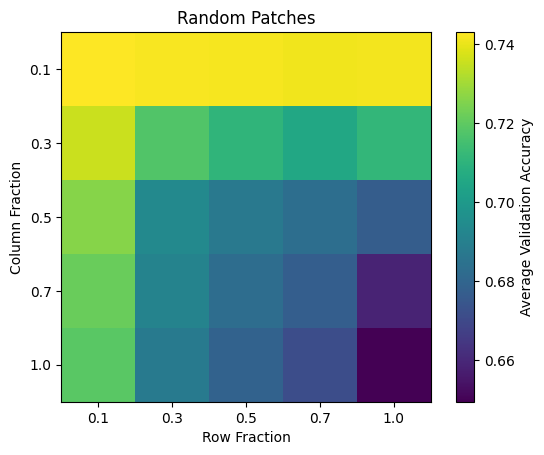

In [ ]:
# part2d - show heatmap
hm = np.mean(ranPatchValidationAccuracies, axis = 0)

fig,ax = plt.subplots()
im = ax.imshow(hm, cmap="viridis")
fig.colorbar(im,ax=ax, label="Average Validation Accuracy")
ax.set_xticks(range(len(sweepRows)))
ax.set_yticks(range(len(sweepRows)))
ax.set_xticklabels(sweepRows)
ax.set_yticklabels(sweepRows)
ax.set_xlabel("Row Fraction")
ax.set_ylabel("Column Fraction")
ax.set_title("Random Patches")

In [ ]:
# part 3a
import math
ranForestEntropyValidationAccuracies = []
ranForestGiniValidationAccuracies = []

ranForestEntropyTrainingTimes = []
ranForestGiniTrainingTimes = []

extraEntropyValidationAccuracies = []
extraGiniValidationAccuracies = []

extraEntropyTrainingTimes = []
extraGiniTrainingTimes = []

p = 28*28 #fashionmnist feature size = image dims
maxFeatures = [1, round(math.sqrt(p)), round(math.log2(p)), round(0.1*p), round(0.3*p), p]

for l in range(len(RANDOM_SEEDS)):
    print(l)

    currRanForestEntropyValidationAccuracies = []
    currRanForestGiniValidationAccuracies = []

    currRanForestEntropyTrainingTimes = []
    currRanForestGiniTrainingTimes = []
    
    currExtraEntropyValidationAccuracies = []
    currExtraGiniValidationAccuracies = []

    currExtraEntropyTrainingTimes = []
    currExtraGiniTrainingTimes = []

    #entropy
    for mf in maxFeatures:
        st = time.time()
        rfEntropy = RandomForestClassifier(
            n_estimators=300,
            criterion='entropy',
            max_features=mf,
            bootstrap=True,
            max_depth=None,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        rfEntropy.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = rfEntropy.predict(xvals[l])
        currRanForestEntropyValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currRanForestEntropyTrainingTimes.append(end-st)

    print("entropy done")
    #gini
    for mf in maxFeatures:
        st = time.time()
        rfGini = RandomForestClassifier(
            n_estimators=300,
            criterion='gini',
            max_features=mf,
            bootstrap=True,
            max_depth=None,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        rfGini.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = rfGini.predict(xvals[l])
        currRanForestGiniValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currRanForestGiniTrainingTimes.append(end-st)
    print("gini done")
    #extra trees entropy
    for mf in maxFeatures:
        st = time.time()
        extraEntropy = ExtraTreesClassifier(
            n_estimators=300,
            criterion='entropy',
            max_features=mf,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        extraEntropy.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = extraEntropy.predict(xvals[l])
        currExtraEntropyValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currExtraEntropyTrainingTimes.append(end-st)

    print("entropy done")
    #extra trees gini
    for mf in maxFeatures:
        st = time.time()
        extraGini = ExtraTreesClassifier(
            n_estimators=300,
            criterion='gini',
            max_features=mf,
            random_state=RANDOM_SEEDS[l],
            n_jobs=-1 # to compute faster
        )
        extraGini.fit(xtrs[l], ytrs[l])
        end = time.time()

        preds = extraGini.predict(xvals[l])
        currExtraGiniValidationAccuracies.append(accuracy_score(yvals[l], preds))
        currExtraGiniTrainingTimes.append(end-st)
    print("gini done")
    
    ranForestEntropyValidationAccuracies.append(currRanForestEntropyValidationAccuracies)
    ranForestGiniValidationAccuracies.append(currRanForestGiniValidationAccuracies)
    ranForestEntropyTrainingTimes.append(currRanForestEntropyTrainingTimes)
    ranForestGiniTrainingTimes.append(currRanForestGiniTrainingTimes)
    extraEntropyValidationAccuracies.append(currExtraEntropyValidationAccuracies)
    extraGiniValidationAccuracies.append(currExtraGiniValidationAccuracies)
    extraEntropyTrainingTimes.append(currExtraEntropyTrainingTimes)
    extraGiniTrainingTimes.append(currExtraGiniTrainingTimes)
    

0
entropy done
gini done
entropy done
gini done
1
entropy done
gini done
entropy done
gini done
2
entropy done
gini done
entropy done
gini done
3
entropy done
gini done
entropy done
gini done
4
entropy done
gini done
entropy done
gini done


In [ ]:
# part 3 calc stats
ranForestEntropyValidationStats = calcStats(ranForestEntropyValidationAccuracies, sweep=maxFeatures)
ranForestGiniValidationStats = calcStats(ranForestGiniValidationAccuracies, sweep=maxFeatures)
ranForestEntropyTimeStats = calcStats(ranForestEntropyTrainingTimes, sweep=maxFeatures)
ranForestGiniTimeStats = calcStats(ranForestGiniTrainingTimes, sweep=maxFeatures)
extraEntropyValidationStats = calcStats(extraEntropyValidationAccuracies, sweep=maxFeatures)
extraGiniValidationStats = calcStats(extraGiniValidationAccuracies, sweep=maxFeatures)
extraEntropyTimeStats = calcStats(extraEntropyTrainingTimes, sweep=maxFeatures)
extraGiniTimeStats = calcStats(extraGiniTrainingTimes, sweep=maxFeatures)

C:\Users\jafer\AppData\Local\Temp\ipykernel_8740\1135720745.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [ ]:
# part3a - show stats as table
table = pd.DataFrame({
    'Max Features': maxFeatures,
    'Random Forest Entropy Validation Accuracy' : combine(ranForestEntropyValidationStats),
    'Random Forest Gini Validation Accuracy': combine(ranForestGiniValidationStats),
    'Random Forest Entropy Training Times': combine(ranForestEntropyTimeStats),
    'Random Forest Gini Training Times': combine(ranForestGiniTimeStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Random Forest Entropy vs Gini Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(80)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

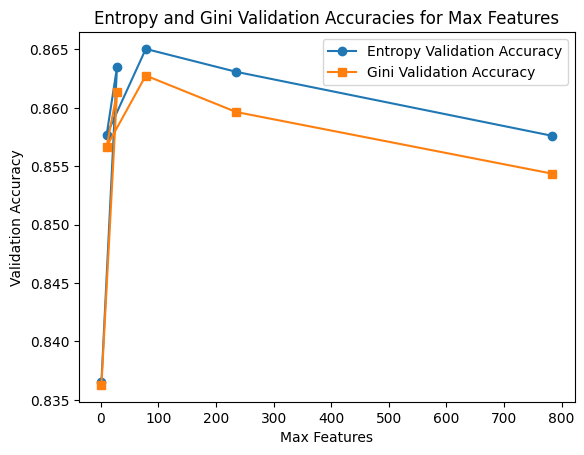

In [ ]:
# part 3a - plot validation accuracy
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyValidationStats], marker='o', label='Entropy Validation Accuracy')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniValidationStats], marker='s', label="Gini Validation Accuracy")
ax.set_xlabel("Max Features")
ax.set_ylabel("Validation Accuracy")
ax.set_title("Entropy and Gini Validation Accuracies for Max Features")
plt.legend()
plt.show()

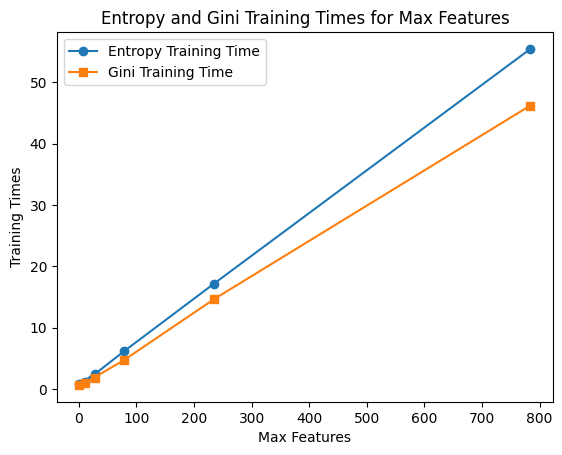

In [ ]:
# part 3a - plot training times
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyTimeStats], marker='o', label='Entropy Training Time')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniTimeStats], marker='s', label="Gini Training Time")
ax.set_xlabel("Max Features")
ax.set_ylabel("Training Times")
ax.set_title("Entropy and Gini Training Times for Max Features")
plt.legend()
plt.show()

C:\Users\jafer\AppData\Local\Temp\ipykernel_8740\157615286.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [ ]:
# part3b - show stats as table
table = pd.DataFrame({
    'Max Features': maxFeatures,
    'Extra Trees Entropy Validation Accuracy' : combine(extraEntropyValidationStats),
    'Extra Trees Gini Validation Accuracy': combine(extraGiniValidationStats),
    'Extra Trees Entropy Training Times': combine(extraEntropyTimeStats),
    'Extra Trees Gini Training Times': combine(extraGiniTimeStats),
})
fig, ax = plt.subplots(figsize=(30,30))
fig.suptitle("Extra Trees Entropy vs Gini Stats", fontsize=120)
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.set_fontsize(100)
axtable.scale(8,20)
axtable.set
plt.tight_layout()
plt.show()

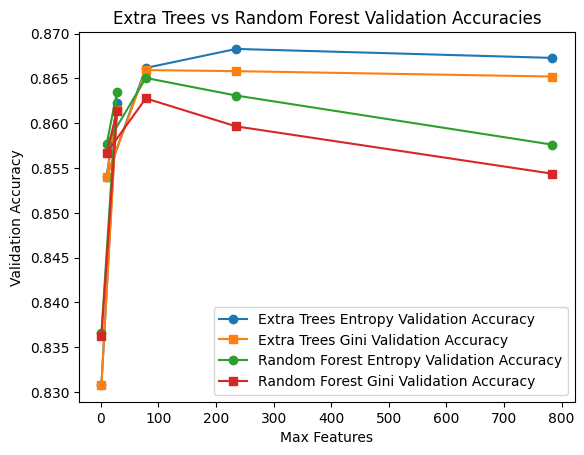

In [ ]:
# part 3b - plot validation accuracy
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in extraEntropyValidationStats], marker='o', label='Extra Trees Entropy Validation Accuracy')
ax.plot(maxFeatures, [i[0] for i in extraGiniValidationStats], marker='s', label="Extra Trees Gini Validation Accuracy")
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyValidationStats], marker='o', label='Random Forest Entropy Validation Accuracy')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniValidationStats], marker='s', label="Random Forest Gini Validation Accuracy")
ax.set_xlabel("Max Features")
ax.set_ylabel("Validation Accuracy")
ax.set_title("Extra Trees vs Random Forest Validation Accuracies")
plt.legend()
plt.show()

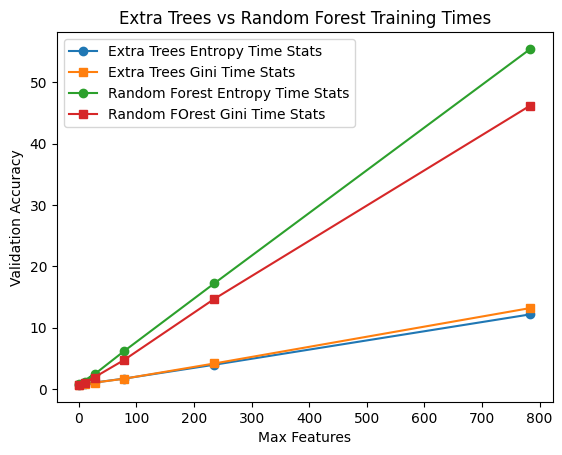

In [ ]:
# part 3b - plot validation accuracy
fig,ax = plt.subplots()
ax.plot(maxFeatures, [i[0] for i in extraEntropyTimeStats], marker='o', label='Extra Trees Entropy Time Stats')
ax.plot(maxFeatures, [i[0] for i in extraGiniTimeStats], marker='s', label="Extra Trees Gini Time Stats")
ax.plot(maxFeatures, [i[0] for i in ranForestEntropyTimeStats], marker='o', label='Random Forest Entropy Time Stats')
ax.plot(maxFeatures, [i[0] for i in ranForestGiniTimeStats], marker='s', label="Random FOrest Gini Time Stats")
ax.set_xlabel("Max Features")
ax.set_ylabel("Validation Accuracy")
ax.set_title("Extra Trees vs Random Forest Training Times")
plt.legend()
plt.show()

In [ ]:
# part 3c - feature importance - classification
#best model was extra trees with 200 max features and entropy
bestExtraEntropy = ExtraTreesClassifier(
    n_estimators=300,
    criterion='entropy',
    max_features=200,
    random_state=RANDOM_SEEDS[0],
    n_jobs=-1 # to compute faster
)
bestExtraEntropy.fit(xtrs[0], ytrs[0])

impureImports = bestExtraEntropy.feature_importances_
perm = permutation_importance(
    bestExtraEntropy,
    xvals[0],
    yvals[0],
    random_state=RANDOM_SEEDS[0],
    scoring='accuracy',
    n_jobs=-1
)
permImports = perm.importances_mean
impureReshape = impureImports.reshape(28, 28)
permReshape = permImports.reshape(28, 28)

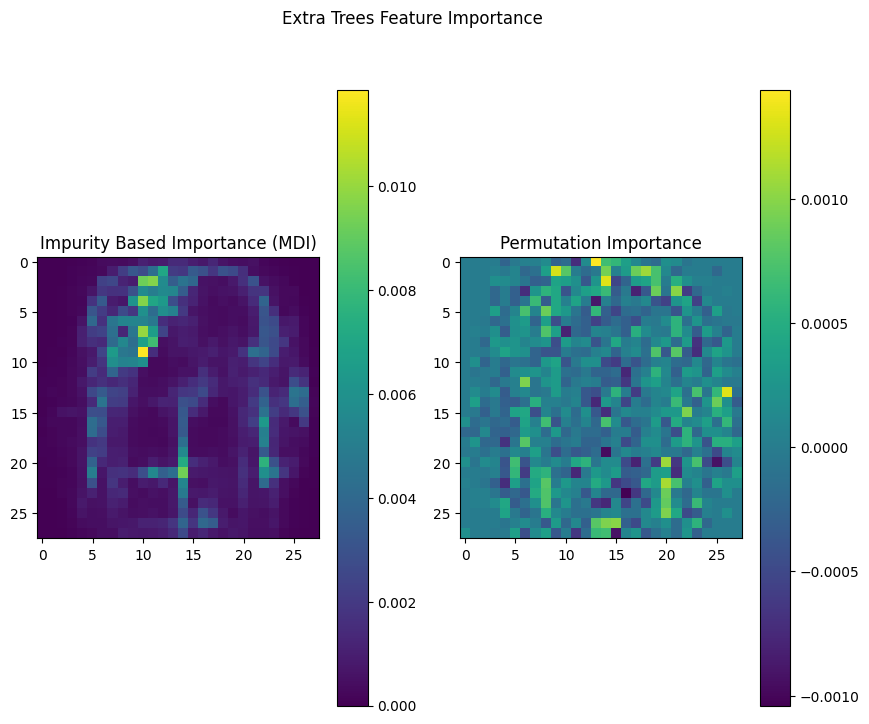

In [ ]:
# part 3c - heatmap - classification
fig, axes = plt.subplots(1, 2, figsize=(10,8))

im1 = axes[0].imshow(impureReshape, cmap='viridis')
axes[0].set_title("Impurity Based Importance (MDI)")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(permReshape, cmap='viridis')
axes[1].set_title("Permutation Importance")
fig.colorbar(im2, ax=axes[1])

plt.suptitle("Extra Trees Feature Importance")
plt.show()

In [ ]:
# part 3c - feature importance - regression
#use extra trees with 200 max features
etRegressor = ExtraTreesRegressor(
    n_estimators=300,
    criterion='squared_error',#faster than absolute
    max_features=200,
    random_state=RANDOM_SEEDS[0],
    n_jobs=-1 # to compute faster
)
etRegressor.fit(regxtrs[0], regytrs[0])

regFI = etRegressor.feature_importances_
perm = permutation_importance(
    etRegressor,
    regxvals[0],
    regyvals[0],
    random_state=RANDOM_SEEDS[0],
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
regPI = perm.importances_mean

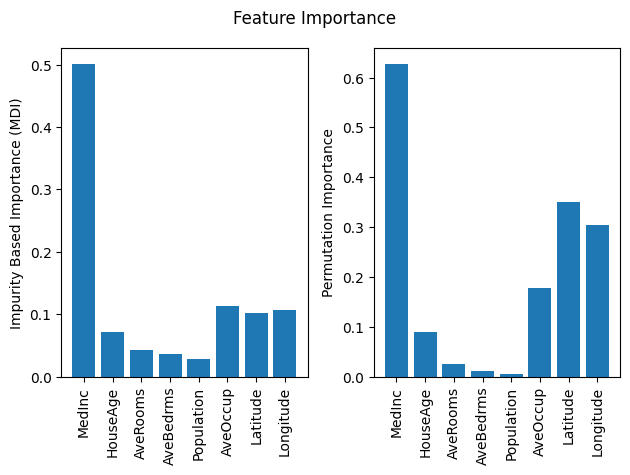

In [ ]:
# part 3c - bar chart
features = californiaHousing.feature_names

fig, axes = plt.subplots(1, 2)

fig.suptitle("Feature Importance")
axes[0].bar(features, regFI)
axes[0].set_ylabel("Impurity Based Importance (MDI)")
axes[0].tick_params(axis='x', rotation=90)

axes[1].bar(features, regPI)
axes[1].set_ylabel("Permutation Importance")
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

In [10]:
# Part 4 - Setup

from joblib import Parallel, delayed
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
from collections import Counter

ytrsI = [np.asarray(y).astype(int) for y in ytrs]
yvalsI = [np.asarray(y).astype(int) for y in yvals]
CLASS_NAMES = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
NUM_CLASSES = 10

def ms(v):
    return '{:.4f} ± {:.4f}'.format(np.mean(v), np.std(v, ddof=1))

ADA_DEPTHS = [1, 2, 4, 8]
ADA_LRS = [0.1, 0.5, 1.0]
ADA_ROUNDS = 500
QUICK = False          
if QUICK:
    ADA_ROUNDS = 100

In [11]:
# Part 4a.1 - First AdaBoost Run

def run_adaboost(depth, lr, s, ytr=None, rounds=None):
    rounds = ADA_ROUNDS if rounds is None else rounds
    seed = RANDOM_SEEDS[s]
    ytr = ytrsI[s] if ytr is None else ytr          # ytr override is used for the label-noise experiment (4b)
    model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=depth, random_state=seed),
        n_estimators=rounds,
        learning_rate=lr,
        random_state=seed
    )
    st = time.perf_counter()
    model.fit(xtrs[s], ytr)
    fitTime = time.perf_counter() - st

    # staged_predict gives the ensemble prediction after 1, 2, ..., T rounds
    trErr = [1 - accuracy_score(ytr, p) for p in model.staged_predict(xtrs[s])]
    vaErr = [1 - accuracy_score(yvalsI[s], p) for p in model.staged_predict(xvals[s])]
    nFit = len(trErr)

    trErr += [trErr[-1]] * (rounds - nFit)
    vaErr += [vaErr[-1]] * (rounds - nFit)
    return {'depth': depth, 'lr': lr, 'seed': s, 'trainErr': np.array(trErr), 'valErr': np.array(vaErr),
            'nFit': nFit, 'time': fitTime}

def firstZeroRound(trErr):
    z = np.where(np.asarray(trErr) == 0)[0]
    return int(z[0]) + 1 if len(z) else None

In [12]:
# Part 4a.2 - Grid

adaConfigs = [(d, lr) for d in ADA_DEPTHS for lr in ADA_LRS]
adaGrid = Parallel(n_jobs=-1, verbose=5)(delayed(run_adaboost)(d, lr, 0) for d, lr in adaConfigs)
adaGridDict = {(r['depth'], r['lr']): r for r in adaGrid}

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of  12 | elapsed:  5.1min remaining: 15.2min
[Parallel(n_jobs=-1)]: Done   6 out of  12 | elapsed: 13.2min remaining: 13.2min
[Parallel(n_jobs=-1)]: Done   9 out of  12 | elapsed: 24.8min remaining:  8.3min
[Parallel(n_jobs=-1)]: Done  12 out of  12 | elapsed: 45.0min finished


In [13]:
# Part 4a.3 - Summary Table

rows = []
for (d, lr), r in adaGridDict.items():
    fz = firstZeroRound(r['trainErr'])
    rows.append({
        'Depth': d, 'LR': lr, 'Rounds fit': r['nFit'],
        'Final train err': round(r['trainErr'][-1], 4),
        'Final val err': round(r['valErr'][-1], 4),
        'Best val err': round(r['valErr'].min(), 4),
        'Best round': int(r['valErr'].argmin()) + 1,
        'First round train err = 0': fz,
        'Val err at that round': round(r['valErr'][fz-1], 4) if fz else None,
        'Fit time (s)': round(r['time'], 1),
    })
adaGridTable = pd.DataFrame(rows)
adaGridTable

,Depth,LR,Rounds fit,Final train err,Final val err,Best val err,Best round,First round train err = 0,Val err at that round,Fit time (s)
0,1,0.1,500,0.4865,0.4844,0.4816,497,NaN,NaN,269.3
1,1,0.5,500,0.4241,0.4182,0.4108,441,NaN,NaN,270.1
2,1,1.0,500,0.3818,0.3826,0.3668,215,NaN,NaN,269.8
3,2,0.1,500,0.3078,0.3098,0.2608,207,NaN,NaN,738.8
4,2,0.5,500,0.3179,0.3358,0.2652,41,NaN,NaN,738.2
5,2,1.0,500,0.2738,0.2946,0.2804,68,NaN,NaN,739.6
6,4,0.1,500,0.1235,0.1656,0.1588,182,NaN,NaN,1160.2
7,4,0.5,500,0.1093,0.1732,0.1716,307,NaN,NaN,1161.2
8,4,1.0,500,0.1107,0.1862,0.1812,477,NaN,NaN,1164.7
9,8,0.1,500,0.0000,0.1272,0.1246,447,138.0,0.1320,2116.9


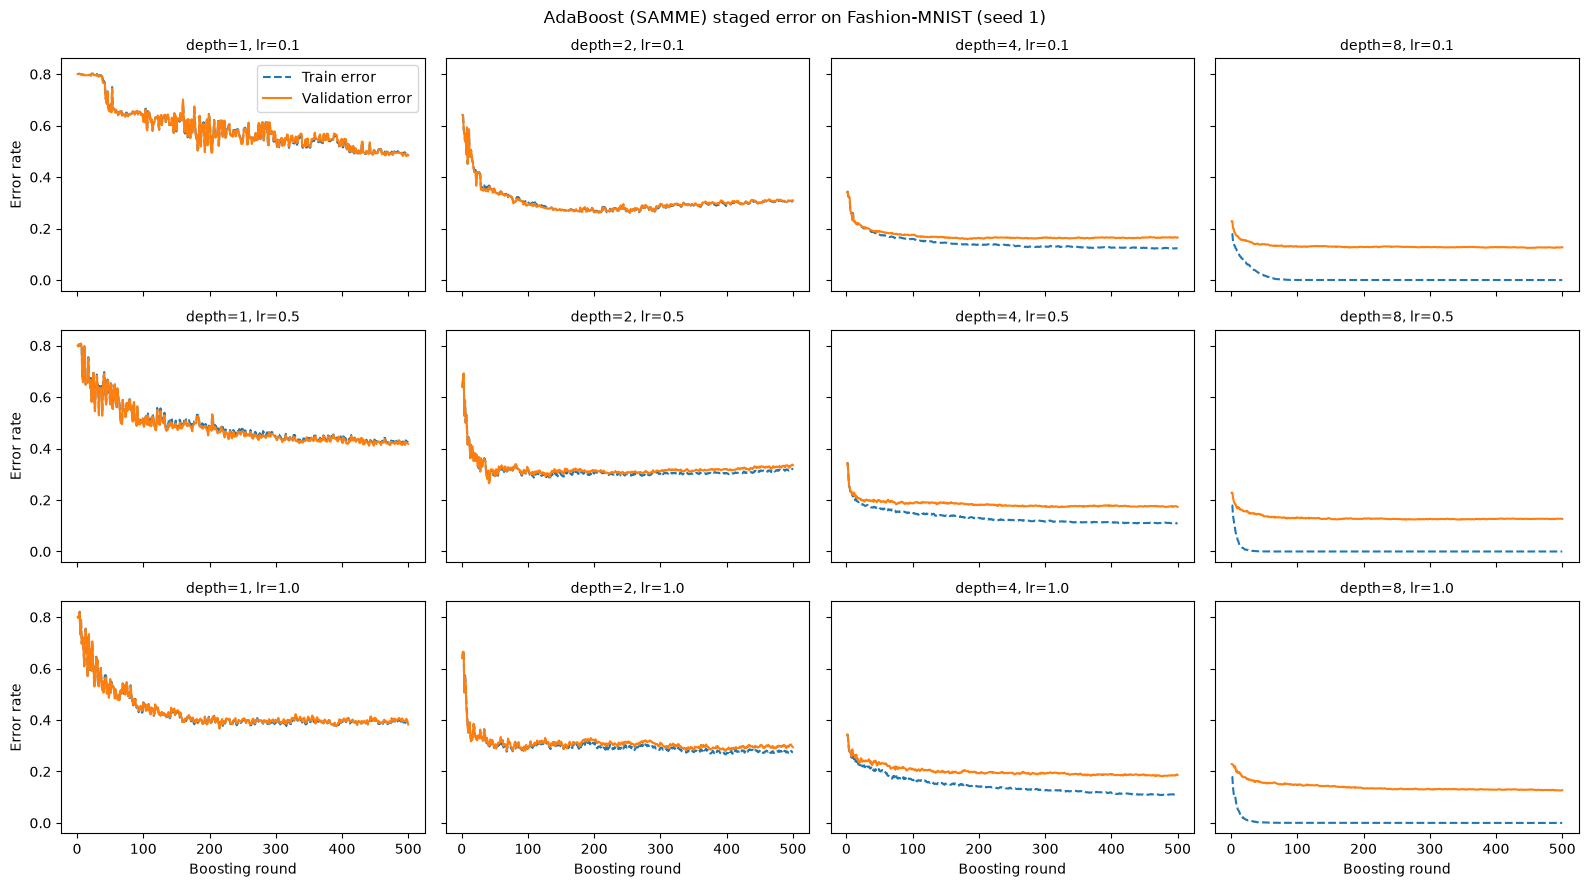

In [14]:
# Part 4a.4 - Plot Staged Errors

fig, axes = plt.subplots(len(ADA_LRS), len(ADA_DEPTHS), figsize=(16, 9), sharex=True, sharey=True)
for i, lr in enumerate(ADA_LRS):
    for j, d in enumerate(ADA_DEPTHS):
        r = adaGridDict[(d, lr)]
        ax = axes[i][j]
        ax.plot(np.arange(1, len(r['trainErr']) + 1), r['trainErr'], linestyle='--', label='Train error')
        ax.plot(np.arange(1, len(r['valErr']) + 1), r['valErr'], label='Validation error')
        ax.set_title('depth={}, lr={}'.format(d, lr), fontsize=10)
        if i == len(ADA_LRS) - 1:
            ax.set_xlabel('Boosting round')
        if j == 0:
            ax.set_ylabel('Error rate')
axes[0][0].legend()
fig.suptitle('AdaBoost (SAMME) staged error on Fashion-MNIST (seed 1)')
plt.tight_layout()
plt.savefig('part4a_staged_error.png', dpi=150)
plt.show()

In [15]:
# Part 4a.5 - Analyze Best Models

bestKey = min(adaGridDict, key=lambda k: adaGridDict[k]['valErr'].min())
bestStumpKey = min([k for k in adaGridDict if k[0] == 1], key=lambda k: adaGridDict[k]['valErr'].min())
bestRound = int(adaGridDict[bestKey]['valErr'].argmin()) + 1
print('Best overall (depth, lr):', bestKey, 'at round', bestRound)
print('Best stump   (depth, lr):', bestStumpKey)

adaSeeds = {}
for key in dict.fromkeys([bestKey, bestStumpKey]):
    others = Parallel(n_jobs=-1, verbose=5)(delayed(run_adaboost)(key[0], key[1], s) for s in range(1, len(RANDOM_SEEDS)))
    adaSeeds[key] = [adaGridDict[key]] + others      # seed index 0 already computed in the grid

for key, runs in adaSeeds.items():
    va = np.array([r['valErr'] for r in runs]); tr = np.array([r['trainErr'] for r in runs])
    print('\n(depth, lr) = {}'.format(key))
    print('  val err  @ final round : {:.4f} ± {:.4f}'.format(va[:, -1].mean(), va[:, -1].std(ddof=1)))
    print('  val err  @ round {:>3}   : {:.4f} ± {:.4f}'.format(bestRound, va[:, bestRound-1].mean(), va[:, bestRound-1].std(ddof=1)))
    print('  train err@ final round : {:.4f} ± {:.4f}'.format(tr[:, -1].mean(), tr[:, -1].std(ddof=1)))
    print('  rounds actually fit    : {}'.format([r['nFit'] for r in runs]))

Best overall (depth, lr): (8, 0.5) at round 343
Best stump   (depth, lr): (1, 1.0)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   4 | elapsed: 25.1min remaining: 25.1min
[Parallel(n_jobs=-1)]: Done   4 out of   4 | elapsed: 25.1min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   4 | elapsed:  2.5min remaining:  2.5min



(depth, lr) = (8, 0.5)
  val err  @ final round : 0.1299 ± 0.0030
  val err  @ round 343   : 0.1296 ± 0.0033
  train err@ final round : 0.0000 ± 0.0000
  rounds actually fit    : [500, 500, 500, 500, 500]

(depth, lr) = (1, 1.0)
  val err  @ final round : 0.4057 ± 0.0218
  val err  @ round 343   : 0.4137 ± 0.0095
  train err@ final round : 0.3985 ± 0.0150
  rounds actually fit    : [500, 500, 500, 500, 500]


[Parallel(n_jobs=-1)]: Done   4 out of   4 | elapsed:  2.5min finished


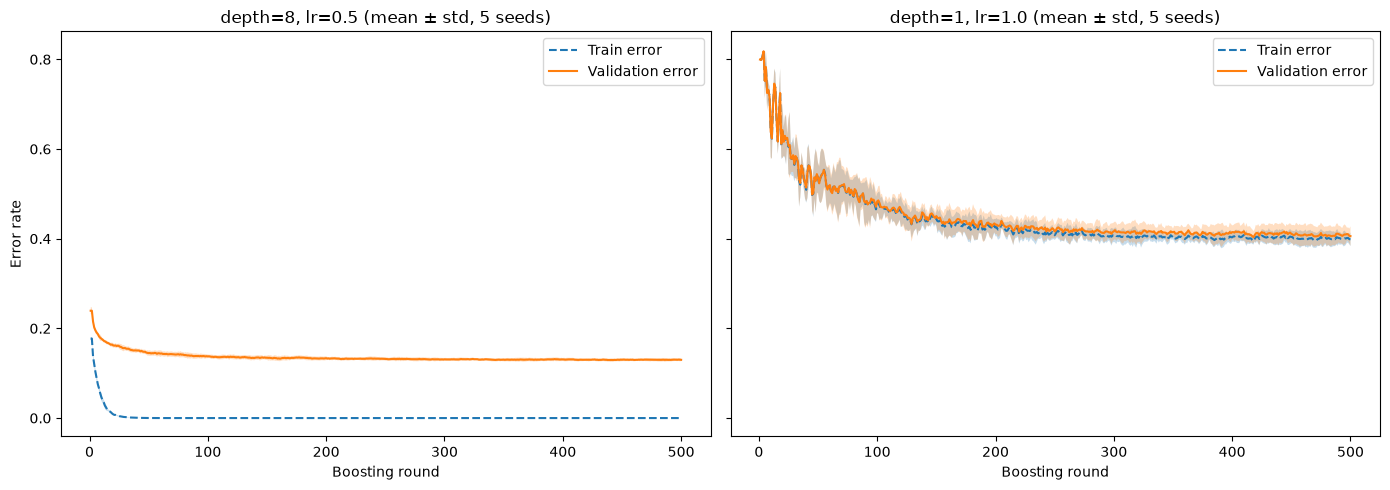

In [16]:
# Part 4a.6 - Plot Best Configurations

fig, axes = plt.subplots(1, len(adaSeeds), figsize=(7 * len(adaSeeds), 5), sharey=True, squeeze=False)
for ax, (key, runs) in zip(axes[0], adaSeeds.items()):
    x = np.arange(1, ADA_ROUNDS + 1)
    for name, field, style in [('Train error', 'trainErr', '--'), ('Validation error', 'valErr', '-')]:
        arr = np.array([r[field] for r in runs])
        mu, sd = arr.mean(axis=0), arr.std(axis=0, ddof=1)
        ax.plot(x, mu, linestyle=style, label=name)
        ax.fill_between(x, mu - sd, mu + sd, alpha=0.25)
    ax.set_title('depth={}, lr={} (mean ± std, 5 seeds)'.format(*key))
    ax.set_xlabel('Boosting round')
    ax.legend()
axes[0][0].set_ylabel('Error rate')
plt.tight_layout()
plt.savefig('part4a_best_configs.png', dpi=150)
plt.show()

In [17]:
# Part 4b.1 - Sample Weights

def adaboost_sample_weights(model, X, y):
    K = len(model.classes_)
    w = np.full(len(y), 1.0 / len(y))
    alphaRecomputed = []
    for est, a in zip(model.estimators_, model.estimator_weights_):
        incorrect = (est.predict(X) != y)
        err = np.sum(w * incorrect)
        alphaRecomputed.append(model.learning_rate * (np.log((1 - err) / err) + np.log(K - 1)))
        w = w * np.exp(a * incorrect)
        w = w / w.sum()
    n = min(len(alphaRecomputed), len(model.estimator_weights_))
    return w, np.max(np.abs(np.array(alphaRecomputed)[:n] - model.estimator_weights_[:n]))

bd, blr = bestKey
ada50 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=bd, random_state=RANDOM_SEEDS[0]),
    n_estimators=50, learning_rate=blr, random_state=RANDOM_SEEDS[0]
)
ada50.fit(xtrs[0], ytrsI[0])
assert len(ada50.estimators_) == 50, len(ada50.estimators_)
w50, alphaDiff = adaboost_sample_weights(ada50, xtrs[0], ytrsI[0])
print('Rounds fit:', len(ada50.estimators_), '| max |alpha_replay - alpha_sklearn| = {:.2e}'.format(alphaDiff))

top = np.argsort(w50)[::-1][:20]
pred50 = ada50.predict(xtrs[0][top])
print('Share of total weight on the top 20 samples : {:.3f}'.format(w50[top].sum()))
print('Share of total weight on the top 1% samples : {:.3f}'.format(np.sort(w50)[::-1][:len(w50)//100].sum()))
print('Max weight / median weight                  : {:.1f}'.format(w50.max() / np.median(w50)))
print('Top-20 still misclassified by the 50-round ensemble: {}/20'.format(int(np.sum(pred50 != ytrsI[0][top]))))
print('True classes among top 20:', Counter(CLASS_NAMES[c] for c in ytrsI[0][top]))


Rounds fit: 50 | max |alpha_replay - alpha_sklearn| = 4.44e-16
Share of total weight on the top 20 samples : 0.077
Share of total weight on the top 1% samples : 0.256
Max weight / median weight                  : 7691.2
Top-20 still misclassified by the 50-round ensemble: 0/20
True classes among top 20: Counter({'Pullover': 5, 'T-shirt/top': 4, 'Coat': 4, 'Dress': 3, 'Trouser': 2, 'Ankle boot': 1, 'Bag': 1})


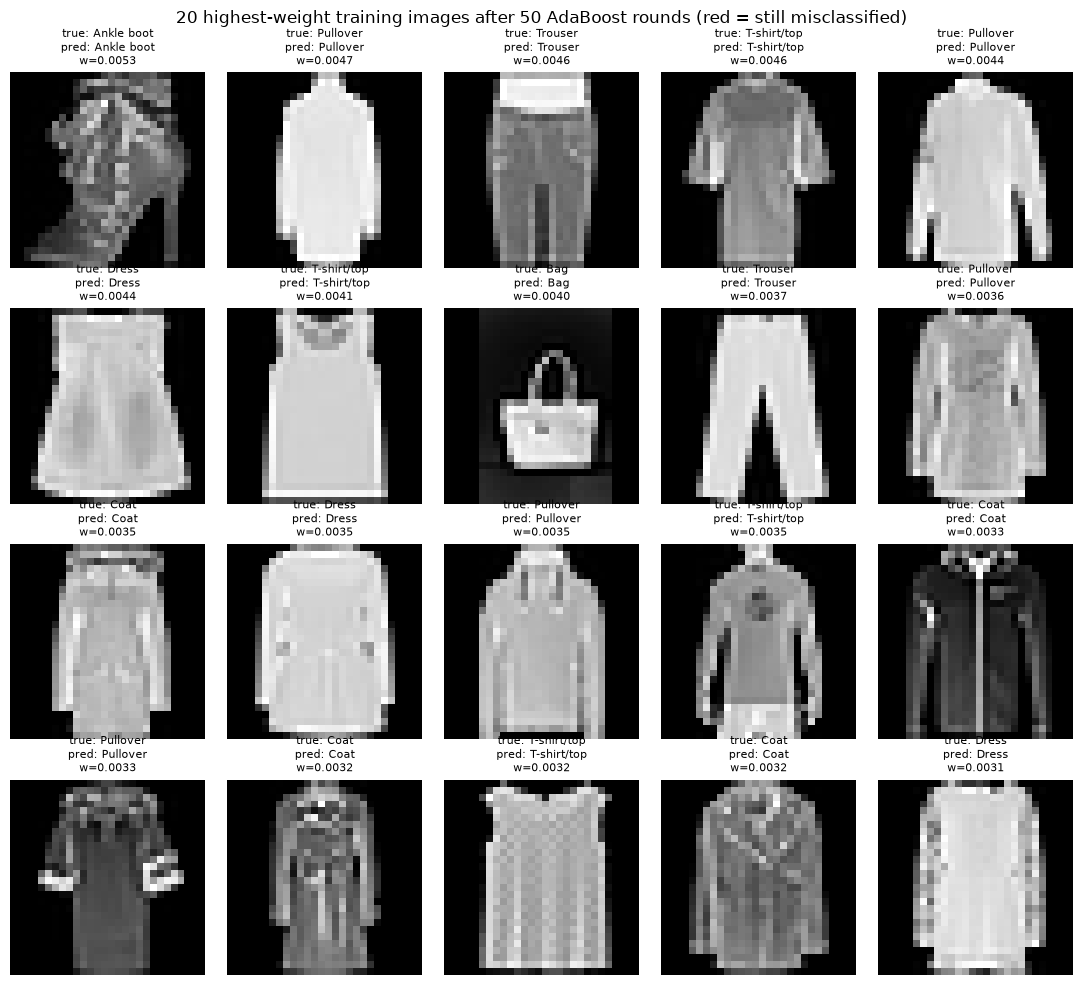

In [18]:
# Part 4b.2 - Visualize Top-Weight Samples

fig, axes = plt.subplots(4, 5, figsize=(11, 10))
for ax, i, p in zip(axes.ravel(), top, pred50):
    ax.imshow(xtrs[0][i].reshape(28, 28), cmap='gray')
    wrong = (p != ytrsI[0][i])
    ax.set_title('true: {}\npred: {}\nw={:.4f}'.format(CLASS_NAMES[ytrsI[0][i]], CLASS_NAMES[p], w50[i]),
                 fontsize=8, color='red' if wrong else 'black')
    ax.axis('off')
fig.suptitle('20 highest-weight training images after 50 AdaBoost rounds (red = still misclassified)')
plt.tight_layout()
plt.savefig('part4b_top_weights.png', dpi=150)
plt.show()

In [19]:
# Part 4b.3 - Noise Robustness

NOISE = 0.10
RF_PARAMS = dict(n_estimators=300, criterion='gini', max_features=28)

def flip_labels(y, frac, seed):
    rng = np.random.default_rng(seed)
    y2 = y.copy()
    idx = rng.choice(len(y), size=int(round(frac * len(y))), replace=False)
    y2[idx] = (y2[idx] + rng.integers(1, NUM_CLASSES, size=len(idx))) % NUM_CLASSES
    return y2, idx

noisyLabels, flippedIdx = [], []
for s in range(len(RANDOM_SEEDS)):
    yn, fi = flip_labels(ytrsI[s], NOISE, RANDOM_SEEDS[s])
    noisyLabels.append(yn); flippedIdx.append(fi)

adaNoisy = Parallel(n_jobs=-1, verbose=5)(delayed(run_adaboost)(bd, blr, s, ytr=noisyLabels[s]) for s in range(len(RANDOM_SEEDS)))

def run_rf(s, ytr):
    rf = RandomForestClassifier(**RF_PARAMS, random_state=RANDOM_SEEDS[s], n_jobs=-1)
    rf.fit(xtrs[s], ytr)
    return accuracy_score(yvalsI[s], rf.predict(xvals[s]))
rfClean = [run_rf(s, ytrsI[s]) for s in range(len(RANDOM_SEEDS))]
rfNoisy = [run_rf(s, noisyLabels[s]) for s in range(len(RANDOM_SEEDS))]

adaCleanRuns = adaSeeds[bestKey]
adaCleanAcc = [1 - r['valErr'][bestRound - 1] for r in adaCleanRuns]
adaNoisyAcc = [1 - r['valErr'][bestRound - 1] for r in adaNoisy]
adaCleanFinal = [1 - r['valErr'][-1] for r in adaCleanRuns]
adaNoisyFinal = [1 - r['valErr'][-1] for r in adaNoisy]
noisyBestRound = int(np.mean([r['valErr'] for r in adaNoisy], axis=0).argmin()) + 1
adaNoisyBest = [1 - r['valErr'][noisyBestRound - 1] for r in adaNoisy]

noiseTable = pd.DataFrame({
    'Model': ['AdaBoost (depth={}, lr={}) @ round {}'.format(bd, blr, bestRound),
              'AdaBoost @ round {}'.format(ADA_ROUNDS),
              'AdaBoost @ own best round (clean {}, noisy {})'.format(bestRound, noisyBestRound),
              'Random forest'],
    'Clean val acc': [ms(adaCleanAcc), ms(adaCleanFinal), ms(adaCleanAcc), ms(rfClean)],
    '10% noisy val acc': [ms(adaNoisyAcc), ms(adaNoisyFinal), ms(adaNoisyBest), ms(rfNoisy)],
    'Drop (pts)': [ms(100*(np.array(adaCleanAcc)-np.array(adaNoisyAcc))),
                   ms(100*(np.array(adaCleanFinal)-np.array(adaNoisyFinal))),
                   ms(100*(np.array(adaCleanAcc)-np.array(adaNoisyBest))),
                   ms(100*(np.array(rfClean)-np.array(rfNoisy)))],
})
noiseTable

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed: 18.7min remaining: 28.1min
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed: 19.0min finished


,Model,Clean val acc,10% noisy val acc,Drop (pts)
0,"AdaBoost (depth=8, lr=0.5) @ round 343",0.8704 ± 0.0033,0.8420 ± 0.0066,2.8360 ± 0.3459
1,AdaBoost @ round 500,0.8701 ± 0.0030,0.8447 ± 0.0064,2.5400 ± 0.4062
2,"AdaBoost @ own best round (clean 343, noisy 498)",0.8704 ± 0.0033,0.8456 ± 0.0062,2.4800 ± 0.3140
3,Random forest,0.8613 ± 0.0043,0.8588 ± 0.0038,0.2560 ± 0.2504


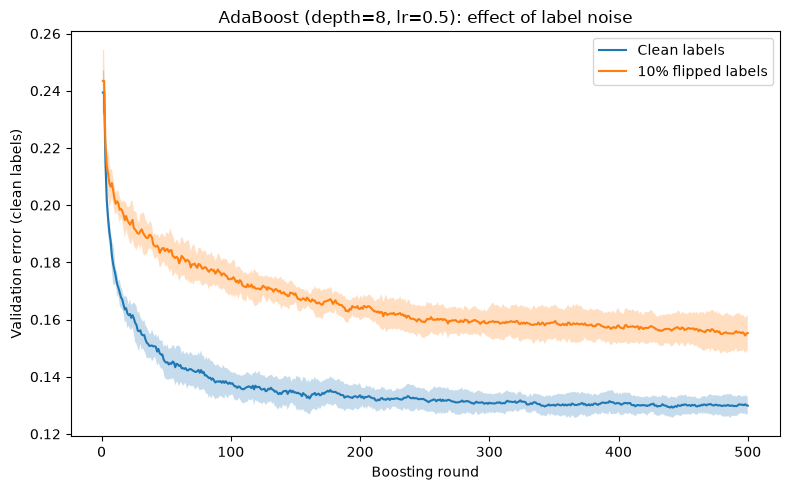

Flipped labels are 10% of the training set but 91% of the 100 highest-weight samples.
Share of total weight held by flipped samples: 0.59


In [20]:
# Part 4b.4 - Plot Noise Robustness

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(1, ADA_ROUNDS + 1)
for name, runs in [('Clean labels', adaCleanRuns), ('10% flipped labels', adaNoisy)]:
    arr = np.array([r['valErr'] for r in runs])
    mu, sd = arr.mean(axis=0), arr.std(axis=0, ddof=1)
    ax.plot(x, mu, label=name)
    ax.fill_between(x, mu - sd, mu + sd, alpha=0.25)
ax.set_xlabel('Boosting round')
ax.set_ylabel('Validation error (clean labels)')
ax.set_title('AdaBoost (depth={}, lr={}): effect of label noise'.format(bd, blr))
ax.legend()
plt.tight_layout()
plt.savefig('part4b_noise_curves.png', dpi=150)
plt.show()

### where does the weight go when labels are noisy? (seed index 0, 50 rounds)
ada50n = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=bd, random_state=RANDOM_SEEDS[0]),
    n_estimators=50, learning_rate=blr, random_state=RANDOM_SEEDS[0]
)
ada50n.fit(xtrs[0], noisyLabels[0])
w50n, _ = adaboost_sample_weights(ada50n, xtrs[0], noisyLabels[0])
isFlipped = np.zeros(len(w50n), dtype=bool); isFlipped[flippedIdx[0]] = True
top100 = np.argsort(w50n)[::-1][:100]
print('Flipped labels are {:.0%} of the training set but {:.0%} of the 100 highest-weight samples.'.format(
    isFlipped.mean(), isFlipped[top100].mean()))
print('Share of total weight held by flipped samples: {:.2f}'.format(w50n[isFlipped].sum()))

In [21]:
# Part 4c.1 - HistGradientBoostingClassifier

HGB_LRS = [0.03, 0.1, 0.3]
HGB_DEPTHS = [2, 4, 8]
HGB_MAX_ITER = 500

def run_hgb(lr, depth, s):
    seed = RANDOM_SEEDS[s]
    m = HistGradientBoostingClassifier(
        learning_rate=lr, max_depth=depth, max_leaf_nodes=None,     # let depth (not the default 31-leaf cap) control size
        max_iter=HGB_MAX_ITER, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=20, scoring='loss', random_state=seed
    )
    st = time.perf_counter()
    m.fit(xtrs[s], ytrsI[s])
    fitTime = time.perf_counter() - st
    curve = [accuracy_score(yvalsI[s], p) for p in m.staged_predict(xvals[s])]
    return {'lr': lr, 'depth': depth, 'seed': s, 'nIter': m.n_iter_, 'time': fitTime, 'valAccCurve': np.array(curve),
            'valAcc': curve[-1], 'valF1': f1_score(yvalsI[s], m.predict(xvals[s]), average='macro'),
            'trainAcc': m.score(xtrs[s], ytrsI[s])}

hgbGrid = {}
for d in HGB_DEPTHS:
    for lr in HGB_LRS:
        hgbGrid[(lr, d)] = run_hgb(lr, d, 0)
        print('lr={}, depth={}: stopped at {} rounds, val acc {:.4f}, {:.1f}s'.format(
            lr, d, hgbGrid[(lr, d)]['nIter'], hgbGrid[(lr, d)]['valAcc'], hgbGrid[(lr, d)]['time']))

hgbTable = pd.DataFrame([{'LR': k[0], 'Depth': k[1], 'Rounds (early stop, incl. 20 patience)': r['nIter'], 'Train acc': round(r['trainAcc'], 4),
                          'Val acc': round(r['valAcc'], 4), 'Val macro-F1': round(r['valF1'], 4), 'Fit time (s, under parallel load)': round(r['time'], 1)}
                         for k, r in hgbGrid.items()])
hgbTable

lr=0.03, depth=2: stopped at 500 rounds, val acc 0.8678, 29.3s
lr=0.1, depth=2: stopped at 256 rounds, val acc 0.8752, 13.8s
lr=0.3, depth=2: stopped at 57 rounds, val acc 0.7958, 3.2s
lr=0.03, depth=4: stopped at 393 rounds, val acc 0.8828, 50.9s
lr=0.1, depth=4: stopped at 127 rounds, val acc 0.8784, 16.5s
lr=0.3, depth=4: stopped at 49 rounds, val acc 0.8694, 7.0s
lr=0.03, depth=8: stopped at 180 rounds, val acc 0.8764, 104.3s
lr=0.1, depth=8: stopped at 68 rounds, val acc 0.8768, 36.9s
lr=0.3, depth=8: stopped at 32 rounds, val acc 0.8770, 16.7s


,LR,Depth,"Rounds (early stop, incl. 20 patience)",Train acc,Val acc,Val macro-F1,"Fit time (s, under parallel load)"
0,0.03,2,500,0.9413,0.8678,0.8668,29.3
1,0.10,2,256,0.9704,0.8752,0.8746,13.8
2,0.30,2,57,0.8652,0.7958,0.7942,3.2
3,0.03,4,393,0.9875,0.8828,0.8823,50.9
4,0.10,4,127,0.9878,0.8784,0.8776,16.5
5,0.30,4,49,0.9870,0.8694,0.8689,7.0
6,0.03,8,180,0.9884,0.8764,0.8749,104.3
7,0.10,8,68,0.9888,0.8768,0.8754,36.9
8,0.30,8,32,0.9875,0.8770,0.8759,16.7


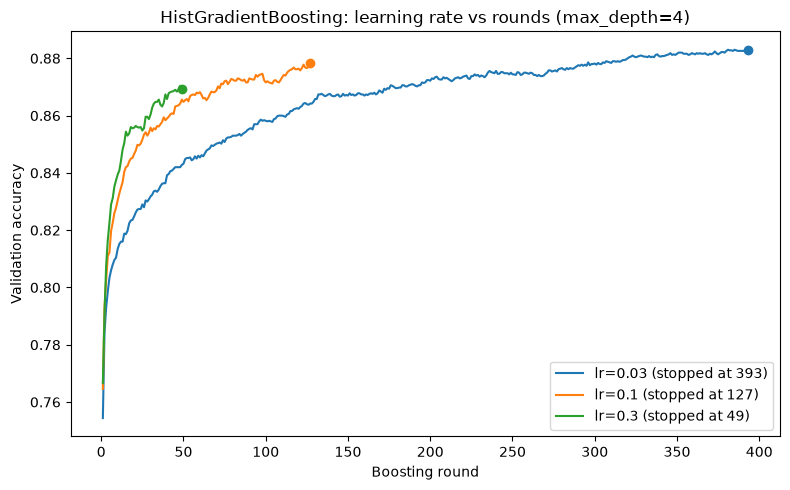

Best HGB (lr, depth) = (0.03, 4)
  val acc  : 0.8742 ± 0.0058
  val F1   : 0.8741 ± 0.0056
  rounds   : 366.2000 ± 34.8023
  fit time : 44.0139 ± 6.5144


In [22]:
# Part 4c.2 - Plot Learning Rate vs Rounds

hgbBestKey = max(hgbGrid, key=lambda k: hgbGrid[k]['valAcc'])
hgbBestDepth = hgbBestKey[1]
fig, ax = plt.subplots(figsize=(8, 5))
for lr in HGB_LRS:
    r = hgbGrid[(lr, hgbBestDepth)]
    line, = ax.plot(np.arange(1, len(r['valAccCurve']) + 1), r['valAccCurve'], label='lr={} (stopped at {})'.format(lr, r['nIter']))
    ax.plot(r['nIter'], r['valAccCurve'][-1], 'o', color=line.get_color())
ax.set_xlabel('Boosting round')
ax.set_ylabel('Validation accuracy')
ax.set_title('HistGradientBoosting: learning rate vs rounds (max_depth={})'.format(hgbBestDepth))
ax.legend()
plt.tight_layout()
plt.savefig('part4c_hgb_lr_rounds.png', dpi=150)
plt.show()

hgbRuns = [hgbGrid[hgbBestKey]] + [run_hgb(hgbBestKey[0], hgbBestKey[1], s) for s in range(1, len(RANDOM_SEEDS))]
print('Best HGB (lr, depth) =', hgbBestKey)
print('  val acc  : ' + ms([r['valAcc'] for r in hgbRuns]))
print('  val F1   : ' + ms([r['valF1'] for r in hgbRuns]))
print('  rounds   : ' + ms([r['nIter'] for r in hgbRuns]))
print('  fit time : ' + ms([r['time'] for r in hgbRuns]))

In [23]:
# Part 4c.3 - Gradient Boosting Regressor

GBR_LRS = [0.03, 0.1, 0.3]
GBR_DEPTHS = [2, 3, 4, 6]
GBR_MAX_EST = 2000

def run_gbr(lr, depth, s):
    seed = RANDOM_SEEDS[s]
    m = GradientBoostingRegressor(
        learning_rate=lr, max_depth=depth, n_estimators=GBR_MAX_EST,
        validation_fraction=0.1, n_iter_no_change=20, tol=1e-4, random_state=seed   # early stopping on an internal split of the training data
    )
    st = time.perf_counter()
    m.fit(regxtrs[s], regytrs[s])
    fitTime = time.perf_counter() - st
    rmse, mae = [], []
    for p in m.staged_predict(regxvals[s]):
        rmse.append(root_mean_squared_error(regyvals[s], p)); mae.append(mean_absolute_error(regyvals[s], p))
    return {'lr': lr, 'depth': depth, 'seed': s, 'nEst': m.n_estimators_, 'time': fitTime,
            'rmseCurve': np.array(rmse), 'maeCurve': np.array(mae), 'rmse': rmse[-1], 'mae': mae[-1]}

gbrGrid = {}
for d in GBR_DEPTHS:
    for lr in GBR_LRS:
        gbrGrid[(lr, d)] = run_gbr(lr, d, 0)
        print('lr={}, depth={}: {} trees, val RMSE {:.4f}'.format(lr, d, gbrGrid[(lr, d)]['nEst'], gbrGrid[(lr, d)]['rmse']))

gbrTable = pd.DataFrame([{'LR': k[0], 'Depth': k[1], 'Trees (early stop, incl. 20 patience)': r['nEst'], 'Val RMSE': round(r['rmse'], 4),
                          'Val MAE': round(r['mae'], 4), 'Fit time (s, under parallel load)': round(r['time'], 1)} for k, r in gbrGrid.items()])
gbrTable

lr=0.03, depth=2: 1747 trees, val RMSE 0.5082
lr=0.1, depth=2: 461 trees, val RMSE 0.5108
lr=0.3, depth=2: 252 trees, val RMSE 0.5026
lr=0.03, depth=3: 972 trees, val RMSE 0.4915
lr=0.1, depth=3: 493 trees, val RMSE 0.4802
lr=0.3, depth=3: 289 trees, val RMSE 0.4766
lr=0.03, depth=4: 783 trees, val RMSE 0.4736
lr=0.1, depth=4: 427 trees, val RMSE 0.4671
lr=0.3, depth=4: 159 trees, val RMSE 0.4800
lr=0.03, depth=6: 558 trees, val RMSE 0.4663
lr=0.1, depth=6: 147 trees, val RMSE 0.4701
lr=0.3, depth=6: 96 trees, val RMSE 0.4830


,LR,Depth,"Trees (early stop, incl. 20 patience)",Val RMSE,Val MAE,"Fit time (s, under parallel load)"
0,0.03,2,1747,0.5082,0.3525,21.0
1,0.10,2,461,0.5108,0.3545,5.3
2,0.30,2,252,0.5026,0.3472,3.1
3,0.03,3,972,0.4915,0.3395,17.6
4,0.10,3,493,0.4802,0.3295,9.1
5,0.30,3,289,0.4766,0.3262,5.1
6,0.03,4,783,0.4736,0.3241,17.2
7,0.10,4,427,0.4671,0.3174,9.2
8,0.30,4,159,0.4800,0.3296,3.5
9,0.03,6,558,0.4663,0.3170,19.4


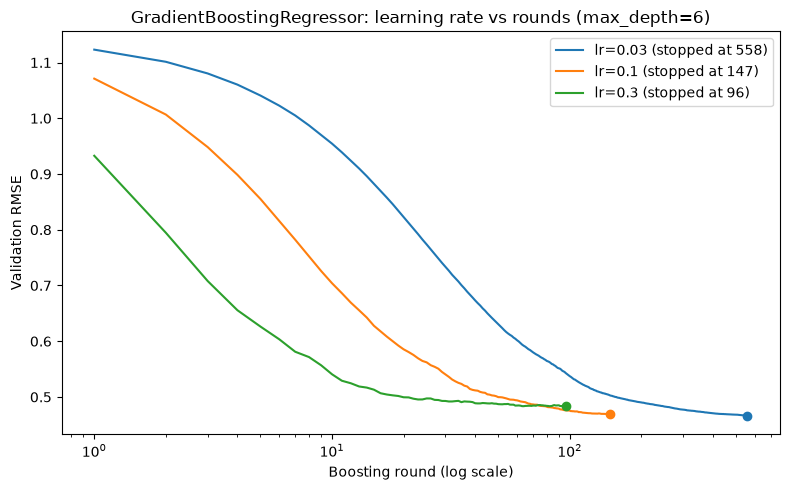

In [24]:
# Part 4c.4 - Plot Learning Rate vs Rounds

gbrBestKey = min(gbrGrid, key=lambda k: gbrGrid[k]['rmse'])
gbrBestDepth = gbrBestKey[1]
fig, ax = plt.subplots(figsize=(8, 5))
for lr in GBR_LRS:
    r = gbrGrid[(lr, gbrBestDepth)]
    line, = ax.plot(np.arange(1, len(r['rmseCurve']) + 1), r['rmseCurve'], label='lr={} (stopped at {})'.format(lr, r['nEst']))
    ax.plot(r['nEst'], r['rmseCurve'][-1], 'o', color=line.get_color())
ax.set_xscale('log')
ax.set_xlabel('Boosting round (log scale)')
ax.set_ylabel('Validation RMSE')
ax.set_title('GradientBoostingRegressor: learning rate vs rounds (max_depth={})'.format(gbrBestDepth))
ax.legend()
plt.tight_layout()
plt.savefig('part4c_gbr_lr_rounds.png', dpi=150)
plt.show()

In [25]:
# Part 4c.5 - AdaBoost.R2

ADAR_DEPTHS = [3, 5, 8]
ADAR_LRS = [0.1, 0.5, 1.0]
ADAR_LOSSES = ['linear', 'square', 'exponential']
ADAR_ROUNDS = 200

def run_adar2(depth, lr, loss, s):
    seed = RANDOM_SEEDS[s]
    m = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=depth, random_state=seed),
        n_estimators=ADAR_ROUNDS, learning_rate=lr, loss=loss, random_state=seed
    )
    m.fit(regxtrs[s], regytrs[s])
    rmse, mae = [], []
    for p in m.staged_predict(regxvals[s]):
        rmse.append(root_mean_squared_error(regyvals[s], p)); mae.append(mean_absolute_error(regyvals[s], p))
    nFit = len(rmse)
    rmse += [rmse[-1]] * (ADAR_ROUNDS - nFit); mae += [mae[-1]] * (ADAR_ROUNDS - nFit)   # pad if it stopped early
    return {'depth': depth, 'lr': lr, 'loss': loss, 'seed': s, 'nFit': nFit,
            'rmseCurve': np.array(rmse), 'maeCurve': np.array(mae)}

adarConfigs = [(d, lr, ls) for d in ADAR_DEPTHS for lr in ADAR_LRS for ls in ADAR_LOSSES]
adarGrid = Parallel(n_jobs=-1, verbose=5)(delayed(run_adar2)(d, lr, ls, 0) for d, lr, ls in adarConfigs)
adarGridDict = {(r['depth'], r['lr'], r['loss']): r for r in adarGrid}
adarBestKey = min(adarGridDict, key=lambda k: adarGridDict[k]['rmseCurve'].min())
adarBestRound = int(adarGridDict[adarBestKey]['rmseCurve'].argmin()) + 1
print('Best AdaBoost.R2 (depth, lr, loss):', adarBestKey, 'at round', adarBestRound)

print('At grid edge? depth:', adarBestKey[0] == max(ADAR_DEPTHS),
    '| lr:', adarBestKey[1] == max(ADAR_LRS),
    '| round:', adarBestRound >= ADAR_ROUNDS - 5)

adarTable = pd.DataFrame([{'Depth': k[0], 'LR': k[1], 'Loss': k[2], 'Best val RMSE': round(r['rmseCurve'].min(), 4),
                           'Best round': int(r['rmseCurve'].argmin()) + 1} for k, r in adarGridDict.items()]).sort_values('Best val RMSE')
adarTable.head(10)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    5.2s
[Parallel(n_jobs=-1)]: Done  18 out of  27 | elapsed:   29.0s remaining:   14.5s
[Parallel(n_jobs=-1)]: Done  24 out of  27 | elapsed:   45.3s remaining:    5.6s


Best AdaBoost.R2 (depth, lr, loss): (8, 0.1, 'square') at round 200
At grid edge? depth: True | lr: False | round: True


[Parallel(n_jobs=-1)]: Done  27 out of  27 | elapsed:   54.5s finished


,Depth,LR,Loss,Best val RMSE,Best round
19,8,0.1,square,0.5404,200
24,8,1.0,linear,0.5435,35
22,8,0.5,square,0.5436,100
18,8,0.1,linear,0.5441,174
20,8,0.1,exponential,0.5453,200
25,8,1.0,square,0.5453,126
21,8,0.5,linear,0.5479,59
23,8,0.5,exponential,0.5488,36
26,8,1.0,exponential,0.5532,34
17,5,1.0,exponential,0.6439,8


In [26]:
# Part 4c.6 - Compare Regression Models

gbrRuns = [gbrGrid[gbrBestKey]] + [run_gbr(gbrBestKey[0], gbrBestKey[1], s) for s in range(1, len(RANDOM_SEEDS))]
adarRuns = [adarGridDict[adarBestKey]] + [run_adar2(*adarBestKey, s) for s in range(1, len(RANDOM_SEEDS))]

# baseline: best single regression tree per seed (depth chosen on validation)
treeRmse, treeMae = [], []
for s in range(len(RANDOM_SEEDS)):
    best = None
    for d in [4, 6, 8, 10]:
        t = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_SEEDS[s]).fit(regxtrs[s], regytrs[s])
        p = t.predict(regxvals[s]); e = root_mean_squared_error(regyvals[s], p)
        if best is None or e < best[0]:
            best = (e, mean_absolute_error(regyvals[s], p))
    treeRmse.append(best[0]); treeMae.append(best[1])

regCompare = pd.DataFrame({
    'Model': ['Single tree (best depth)',
              'GradientBoosting (lr={}, depth={})'.format(*gbrBestKey),
              'AdaBoost.R2 (depth={}, lr={}, loss={}, {} rounds)'.format(*adarBestKey, adarBestRound)],
    'Val RMSE': [ms(treeRmse), ms([r['rmse'] for r in gbrRuns]), ms([r['rmseCurve'][adarBestRound-1] for r in adarRuns])],
    'Val MAE':  [ms(treeMae),  ms([r['mae'] for r in gbrRuns]),  ms([r['maeCurve'][adarBestRound-1] for r in adarRuns])],
})
regCompare

,Model,Val RMSE,Val MAE
0,Single tree (best depth),0.6448 ± 0.0142,0.4262 ± 0.0090
1,"GradientBoosting (lr=0.03, depth=6)",0.4642 ± 0.0045,0.3089 ± 0.0047
2,"AdaBoost.R2 (depth=8, lr=0.1, loss=square, 200...",0.5425 ± 0.0095,0.4087 ± 0.0100


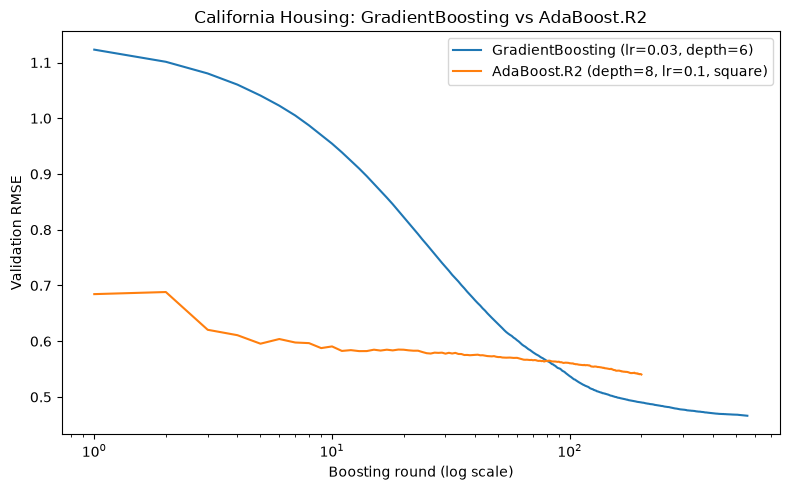

In [27]:
# Part 4c - Plot Regression Curves

fig, ax = plt.subplots(figsize=(8, 5))
rg = gbrRuns[0]; ra = adarRuns[0]
ax.plot(np.arange(1, len(rg['rmseCurve']) + 1), rg['rmseCurve'], label='GradientBoosting (lr={}, depth={})'.format(*gbrBestKey))
ax.plot(np.arange(1, len(ra['rmseCurve']) + 1), ra['rmseCurve'], label='AdaBoost.R2 (depth={}, lr={}, {})'.format(*adarBestKey))
ax.set_xscale('log')
ax.set_xlabel('Boosting round (log scale)')
ax.set_ylabel('Validation RMSE')
ax.set_title('California Housing: GradientBoosting vs AdaBoost.R2')
ax.legend()
plt.tight_layout()
plt.savefig('part4c_reg_compare.png', dpi=150)
plt.show()

In [28]:
# Part 4 - Summary Table

part4Summary = pd.DataFrame({
    'Model': ['AdaBoost (Fashion-MNIST)', 'HistGradientBoosting (Fashion-MNIST)', 'GradientBoostingRegressor (CA Housing)', 'AdaBoost.R2 (CA Housing)'],
    'Best hyperparameters': ['depth={}, lr={}, rounds={}'.format(bd, blr, bestRound),
                             'lr={}, max_depth={}, early-stopped'.format(*hgbBestKey),
                             'lr={}, max_depth={}, early-stopped'.format(*gbrBestKey),
                             'depth={}, lr={}, loss={}, rounds={}'.format(*adarBestKey, adarBestRound)],
    'Validation score (mean ± std, 5 seeds)': [
        'acc ' + ms(adaCleanAcc), 'acc ' + ms([r['valAcc'] for r in hgbRuns]),
        'RMSE ' + ms([r['rmse'] for r in gbrRuns]), 'RMSE ' + ms([r['rmseCurve'][adarBestRound-1] for r in adarRuns])],
})
part4Summary.to_csv('part4_results.csv', index=False)
noiseTable.to_csv('part4b_noise_results.csv', index=False)
part4Summary

,Model,Best hyperparameters,"Validation score (mean ± std, 5 seeds)"
0,AdaBoost (Fashion-MNIST),"depth=8, lr=0.5, rounds=343",acc 0.8704 ± 0.0033
1,HistGradientBoosting (Fashion-MNIST),"lr=0.03, max_depth=4, early-stopped",acc 0.8742 ± 0.0058
2,GradientBoostingRegressor (CA Housing),"lr=0.03, max_depth=6, early-stopped",RMSE 0.4642 ± 0.0045
3,AdaBoost.R2 (CA Housing),"depth=8, lr=0.1, loss=square, rounds=200",RMSE 0.5425 ± 0.0095


In [29]:
# Part 4 - Test-set Evluation

ytesI = [np.asarray(y).astype(int) for y in ytes]
S = range(len(RANDOM_SEEDS))

# AdaBoost classifier at the chosen depth, lr and round
def test_ada(s):
    m = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=bd, random_state=RANDOM_SEEDS[s]),
        n_estimators=bestRound, learning_rate=blr, random_state=RANDOM_SEEDS[s]
    ).fit(xtrs[s], ytrsI[s])
    return accuracy_score(ytesI[s], m.predict(xtes[s]))
adaTest = Parallel(n_jobs=-1)(delayed(test_ada)(s) for s in S)

# HistGradientBoosting
def test_hgb(s):
    m = HistGradientBoostingClassifier(
        learning_rate=hgbBestKey[0], max_depth=hgbBestKey[1], max_leaf_nodes=None,
        max_iter=HGB_MAX_ITER, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=20, scoring='loss', random_state=RANDOM_SEEDS[s]
    ).fit(xtrs[s], ytrsI[s])
    return accuracy_score(ytesI[s], m.predict(xtes[s]))
hgbTest = [test_hgb(s) for s in S]

# GradientBoostingRegressor
def test_gbr(s):
    m = GradientBoostingRegressor(
        learning_rate=gbrBestKey[0], max_depth=gbrBestKey[1], n_estimators=GBR_MAX_EST,
        validation_fraction=0.1, n_iter_no_change=20, tol=1e-4, random_state=RANDOM_SEEDS[s]
    ).fit(regxtrs[s], regytrs[s])
    return root_mean_squared_error(regytes[s], m.predict(regxtes[s]))
gbrTest = [test_gbr(s) for s in S]

# AdaBoost.R2 at the chosen round
def test_adar(s):
    d, lr, ls = adarBestKey
    m = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=d, random_state=RANDOM_SEEDS[s]),
        n_estimators=adarBestRound, learning_rate=lr, loss=ls, random_state=RANDOM_SEEDS[s]
    ).fit(regxtrs[s], regytrs[s])
    return root_mean_squared_error(regytes[s], m.predict(regxtes[s]))
adarTest = [test_adar(s) for s in S]

# Single-tree baseline: pick depth on val, report on test
def test_tree(s):
    best = min([4, 6, 8, 10], key=lambda d: root_mean_squared_error(
        regyvals[s], DecisionTreeRegressor(max_depth=d, random_state=RANDOM_SEEDS[s]).fit(regxtrs[s], regytrs[s]).predict(regxvals[s])))
    t = DecisionTreeRegressor(max_depth=best, random_state=RANDOM_SEEDS[s]).fit(regxtrs[s], regytrs[s])
    return root_mean_squared_error(regytes[s], t.predict(regxtes[s]))
treeTest = [test_tree(s) for s in S]

testTable = pd.DataFrame({
    'Model': ['AdaBoost (Fashion-MNIST)', 'HistGradientBoosting (Fashion-MNIST)',
              'Single tree (CA Housing)', 'GradientBoostingRegressor (CA Housing)', 'AdaBoost.R2 (CA Housing)'],
    'Test score (mean ± std, 5 seeds)': ['acc ' + ms(adaTest), 'acc ' + ms(hgbTest),
                                         'RMSE ' + ms(treeTest), 'RMSE ' + ms(gbrTest), 'RMSE ' + ms(adarTest)],
})
testTable.to_csv('part4_test_results.csv', index=False)
testTable

,Model,"Test score (mean ± std, 5 seeds)"
0,AdaBoost (Fashion-MNIST),acc 0.8621 ± 0.0021
1,HistGradientBoosting (Fashion-MNIST),acc 0.8636 ± 0.0016
2,Single tree (CA Housing),RMSE 0.6508 ± 0.0039
3,GradientBoostingRegressor (CA Housing),RMSE 0.4663 ± 0.0097
4,AdaBoost.R2 (CA Housing),RMSE 0.5394 ± 0.0076


In [30]:
# Part 6 - best tree classification (Gini) hyperparameters
# optimal depth is none, optimal alpha is 0.0006, optimal msl is 20
treeGiniTestAccs = []
treeGiniF1s = []
treeGiniTrainTimes = []
treeGiniPredictTimes = []
treeGiniModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    giniTree = DecisionTreeClassifier(
        criterion="gini",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    giniTree.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    treeGiniTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = giniTree.predict(xtes[l])
    treeGiniTestAccs.append(accuracy_score(ytes[l], preds))
    treeGiniF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    treeGiniPredictTimes.append((end-st) * 100) #10,000 tests images, performance counter is for seconds, 1,000,000/10,000 = 100
    treeGiniModelSizes.append(giniTree.tree_.node_count)
    print(treeGiniTestAccs)

0
[0.766]
1
[0.766, 0.7543]
2
[0.766, 0.7543, 0.774]
3
[0.766, 0.7543, 0.774, 0.7613]
4
[0.766, 0.7543, 0.774, 0.7613, 0.7598]


In [31]:
# Part 6 - best tree classification (Entropy) hyperparameters
# optimal depth is none, optimal alpha is 0.0006, optimal msl is 20
treeEntropyTestAccs = []
treeEntropyF1s = []
treeEntropyTrainTimes = []
treeEntropyPredictTimes = []
treeEntropyModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    entropyTree = DecisionTreeClassifier(
        criterion="entropy",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    entropyTree.fit(xtrs[l], ytrs[l])
    end = time.perf_counter()
    treeEntropyTrainTimes.append(end-st)

    st = time.perf_counter()
    preds = entropyTree.predict(xtes[l])
    treeEntropyTestAccs.append(accuracy_score(ytes[l], preds))
    treeEntropyF1s.append(f1_score(ytes[l], preds, average="macro"))
    end = time.perf_counter()

    treeEntropyPredictTimes.append((end-st) * 100) #10,000 tests images, performance counter is for seconds, 1,000,000/10,000 = 100
    treeEntropyModelSizes.append(entropyTree.tree_.node_count)
    print(treeEntropyTestAccs)

0
[0.7716]
1
[0.7716, 0.7689]
2
[0.7716, 0.7689, 0.7687]
3
[0.7716, 0.7689, 0.7687, 0.7584]
4
[0.7716, 0.7689, 0.7687, 0.7584, 0.7686]


In [32]:
# Part 6 - best tree regression (RMSE) hyperparameters
# optimal depth is none, optimal alpha is 0.0006, optimal msl is 20
treeRegRMSETestRmses = []
treeRegRMSETestMaes= []
treeRegRMSETrainTimes = []
treeRegRMSEPredictTimes = []
treeRegRMSEModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regRMSETree = DecisionTreeRegressor(
        criterion="squared_error",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    regRMSETree.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    treeRegRMSETrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regRMSETree.predict(regxtes[l])
    treeRegRMSETestRmses.append(root_mean_squared_error(regytes[l], preds))
    treeRegRMSETestMaes.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    treeRegRMSEPredictTimes.append((end-st) * 100) #10,000 tests images, performance counter is for seconds, 1,000,000/10,000 = 100
    treeRegRMSEModelSizes.append(regRMSETree.tree_.node_count)
    print(treeRegRMSETestRmses)

0
[0.6103784359013414]
1
[0.6103784359013414, 0.6423001068770358]
2
[0.6103784359013414, 0.6423001068770358, 0.6245818069509597]
3
[0.6103784359013414, 0.6423001068770358, 0.6245818069509597, 0.6171507200321468]
4
[0.6103784359013414, 0.6423001068770358, 0.6245818069509597, 0.6171507200321468, 0.6315322841894897]


In [33]:
# Part 6 - best tree regression (RMSE) hyperparameters
# optimal depth is none, optimal alpha is 0.0006, optimal msl is 20
treeRegMAETestRmses = []
treeRegMAETestMaes= []
treeRegMAETrainTimes = []
treeRegMAEPredictTimes = []
treeRegMAEModelSizes = []

for l in range(len(RANDOM_SEEDS)):
    print(l)
    st = time.perf_counter()
    regMAETree = DecisionTreeRegressor(
        criterion="absolute_error",
        ccp_alpha=0.0006,
        min_samples_leaf=20,
        max_depth=None,
        random_state=RANDOM_SEEDS[l]
    )
    regMAETree.fit(regxtrs[l], regytrs[l])
    end = time.perf_counter()
    treeRegMAETrainTimes.append(end-st)

    st = time.perf_counter()
    preds = regMAETree.predict(regxtes[l])
    treeRegMAETestRmses.append(root_mean_squared_error(regytes[l], preds))
    treeRegMAETestMaes.append(mean_absolute_error(regytes[l], preds))
    end = time.perf_counter()

    treeRegMAEPredictTimes.append((end-st) * 100) #10,000 tests images, performance counter is for seconds, 1,000,000/10,000 = 100
    treeRegMAEModelSizes.append(regMAETree.tree_.node_count)
    print(treeRegMAETestRmses)

0
[0.6426008189200508]
1
[0.6426008189200508, 0.6447113983460099]
2
[0.6426008189200508, 0.6447113983460099, 0.6282585214757183]
3
[0.6426008189200508, 0.6447113983460099, 0.6282585214757183, 0.6381632435723844]
4
[0.6426008189200508, 0.6447113983460099, 0.6282585214757183, 0.6381632435723844, 0.647395169334421]
